In [1]:
import sys
sys.path.append('/Users/blancamartin/Desktop/Voytek_Lab/spike_waveform/spikewise/Action potential waveforms are state-dependent paper/AP_empirical_paper_all_analyses/datasets/pvc-6/pvc6_helper_modules/')



from pvc6_stim_analysis import *
from pvc6_load_data import *
from pvc6_plotting import *


%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from spikewise.patch.fit import Spike, SpikeGroup
from tqdm.notebook import tqdm
import pickle

import seaborn as sns
sns.set(rc={'figure.figsize':(12,9)})
sns.set_style('whitegrid')
sns.set_style("whitegrid", {'axes.grid' : False})

import warnings
warnings.filterwarnings('ignore')
import os

set_plot_style()


In [2]:
# ── Run-control flags ─────────────────────────────────────────────────────────
FORCE_RERUN = False  # set True to recompute and overwrite pickles
PICKLE_DIR  = "/Users/blancamartin/Desktop/Voytek_Lab/spike_waveform/pvc6_pickles/"


## 1. Data Source: PVC-6 (CRCNS) — Cell 2

Same dataset and analysis pipeline as cell 1 (see `spk_waveform_stim_predictors_cell1`), applied to a second recording (151145.04_Data.h5). Replicating across cells tests whether the stimulus-driven waveform variability we observe is a general property of cortical neurons rather than an idiosyncrasy of one recording.

## 2. Data Loading & Preprocessing

### 2a. Raw Data

We open the HDF5 recording and extract sweep-level ephys + stimulus traces at 200 kHz.

In [3]:
fs = 200000 # sampling rate
one_ms = int(fs / 1000)
total_sweeps = 66
filename =  '/Users/blancamartin/Downloads/151145.04_Data.h5' # filename
f = h5py.File(filename, 'r')

### 2b. Sweep Processing & Feature Extraction

For each sweep we label the stimulus type (constant / ramp / pink) and extract per-spike stimulus context. Results are cached to pickle for fast reloading. Note: three sweeps (27, 47, 50) are removed due to incorrect spike counts in the raw data.

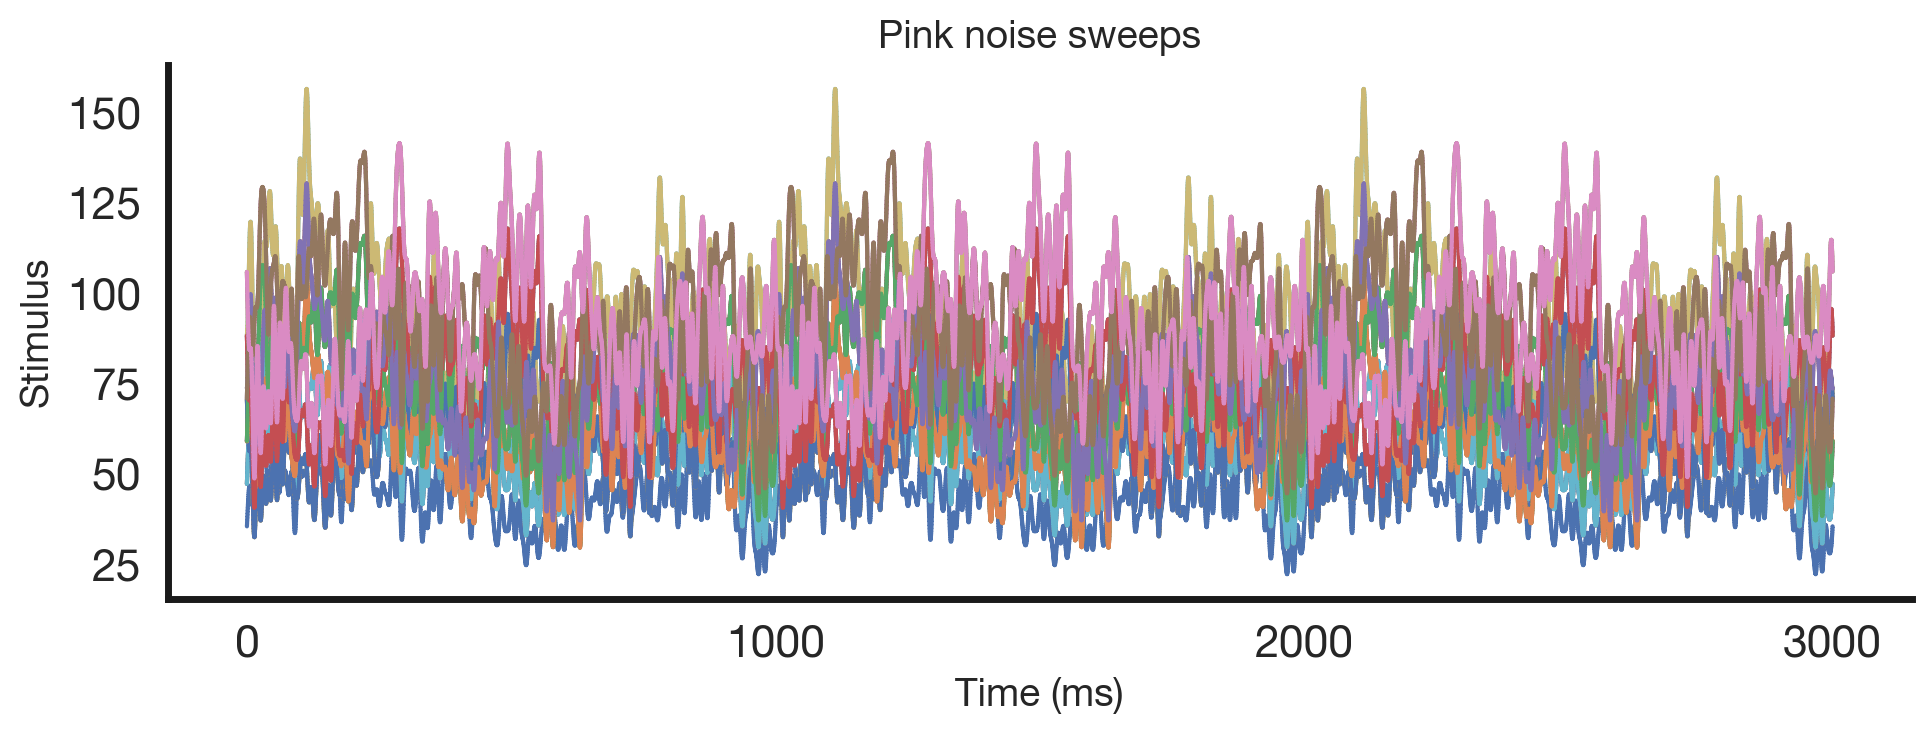

In [4]:
# Process sweeps and extract features
pink_types = process_pink_type_info(f, fs)

In [5]:
_pickle_paths = {
    'stim': os.path.join(PICKLE_DIR, 'df_stim_features2.pkl'),
    'data': os.path.join(PICKLE_DIR, 'all_data2.pkl'),
}
df_stim_features, all_data_flat = load_or_compute_cell_data(
    _pickle_paths, FORCE_RERUN,
    n_sweeps=66, f=f, one_ms=one_ms, fs=fs, pink_types=pink_types,
)

pickle_path_waveform = os.path.join(PICKLE_DIR, 'stim_waveforms2.pkl')
if not FORCE_RERUN and os.path.exists(pickle_path_waveform):
    try:
        with open(pickle_path_waveform, 'rb') as file:
            stim_waveforms = pickle.load(file)
        all_contant_spks, all_ramp_spks, all_pink_spks = stim_waveforms
        print('Loaded stim_waveforms from pickle.')
    except Exception as _e:
        print(f'stim_waveforms pickle load failed ({_e}); recomputing from all_data.')
        stim_waveforms = None
else:
    stim_waveforms = None

if stim_waveforms is None:
    pink_types_local = process_pink_type_info(f, fs)
    (_, _, _, _, _, _, _, _, _, _, _, _, _,
     _, _, _, all_contant_spks, all_ramp_spks, all_pink_spks
    ) = process_sweeps(66, f, one_ms, fs, pink_types_local, load_sweep, find_spike_times, fit_exp_nonlinear)
    stim_waveforms = [all_contant_spks, all_ramp_spks, all_pink_spks]
    with open(pickle_path_waveform, 'wb') as file:
        pickle.dump(stim_waveforms, file)
    print('Saved stim_waveforms to pickle.')


Loaded df_stim_features and all_data from pickle.
Loaded stim_waveforms from pickle.


### 2c. Data Cleaning

Sweeps 27, 47, and 50 have incorrect spike counts in the raw data. We drop these rows before fitting to avoid corrupting the feature distribution.

## 3. Spike Waveform Parameterization

### 3a. Fitting

We fit every spike with the `Spike` class, extracting: peak amplitude, peak sharpness, peak width, exp_lambda, exp_const, inflection time, and log ISI — the same feature set used across all datasets.

In [6]:
sp = Spike(thresh_amp= -10, window_length=(5., 5.), smooth_frac=.008, pre_inflection_ms = 0.5)
sp.fit(all_data_flat, fs, n_jobs=-1, progress=tqdm)

Spike:   0%|          | 0/380 [00:00<?, ?it/s]

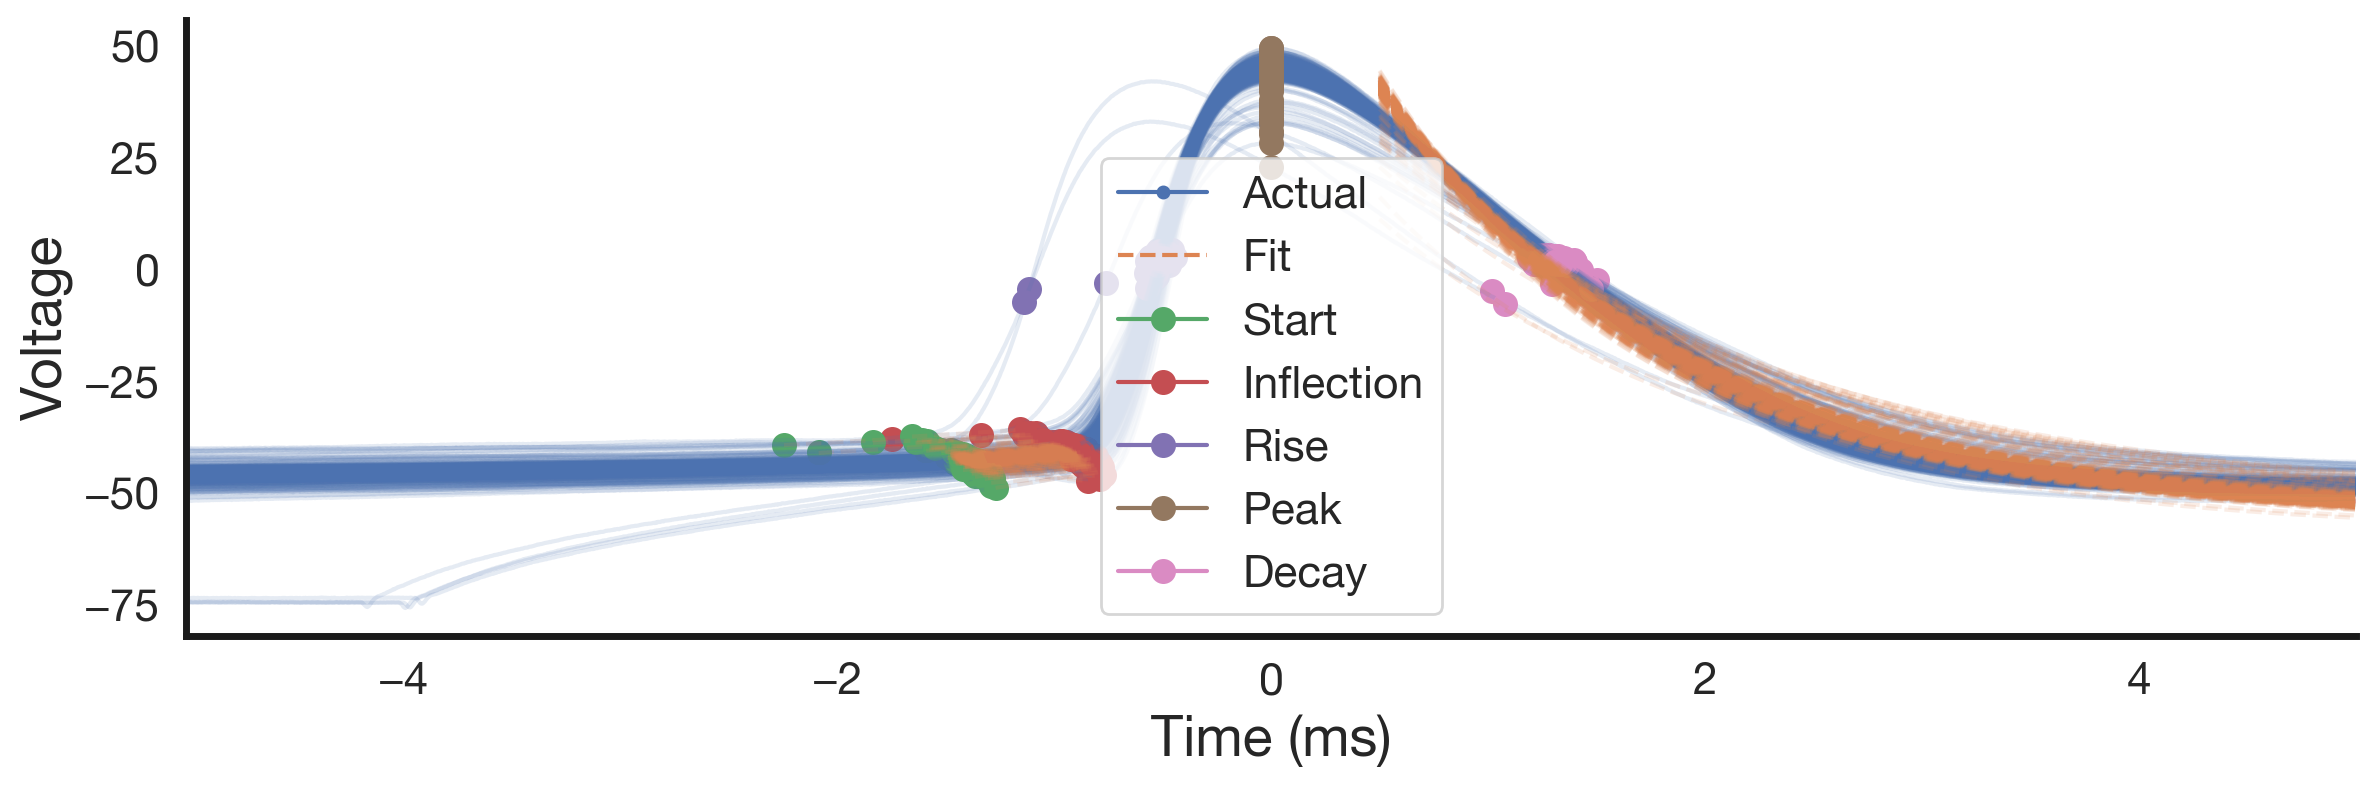

In [7]:
sp.plot(show_points=True)

In [8]:
sp.filter_features()

In [9]:
df_features = sp.df_features

### 3b. Merging with Stimulus Metadata

Concatenate the `Spike` feature DataFrame with the per-spike stimulus table, yielding one row per spike with both waveform parameters and stimulus context.

In [10]:
df = pd.concat([df_stim_features, df_features], axis=1)
df = df.dropna(subset=['stim_type'])

In [11]:
_pkl_all = os.path.join(PICKLE_DIR, 'df_all_c2.pkl')
if FORCE_RERUN or not os.path.exists(_pkl_all):
    with open(_pkl_all, 'wb') as fh:
        pickle.dump(df, fh)
    print('Saved df_all_c2.pkl')

In [12]:
# Assuming your DataFrame is called df and the column for sweeps is 'sweep'

# Identify rows that belong to the sweeps where one row needs to be removed
sweeps_to_fix = [50, 47, 27]

# Create a mask that finds the first occurrence of each sweep in sweeps_to_fix
mask = df_stim_features[df_stim_features['sweep'].isin(sweeps_to_fix)].groupby('sweep').head(1).index

# Drop the first occurrence for each incorrect sweep
df_stim_features = df_stim_features.drop(mask)

# Reset index after removal (optional)
df_stim_features = df_stim_features.reset_index(drop=True)



## 4. Pink Noise Spike Analysis

### 4a. Waveform Gallery

Raw spike waveforms from pink noise sweeps only, showing the within-condition variability that the regression models aim to explain.

In [13]:
pink_spikes = df[df['stim_type'] == 'pink']

# Get the indices to plot
indices_to_plot = pink_spikes.index.tolist()

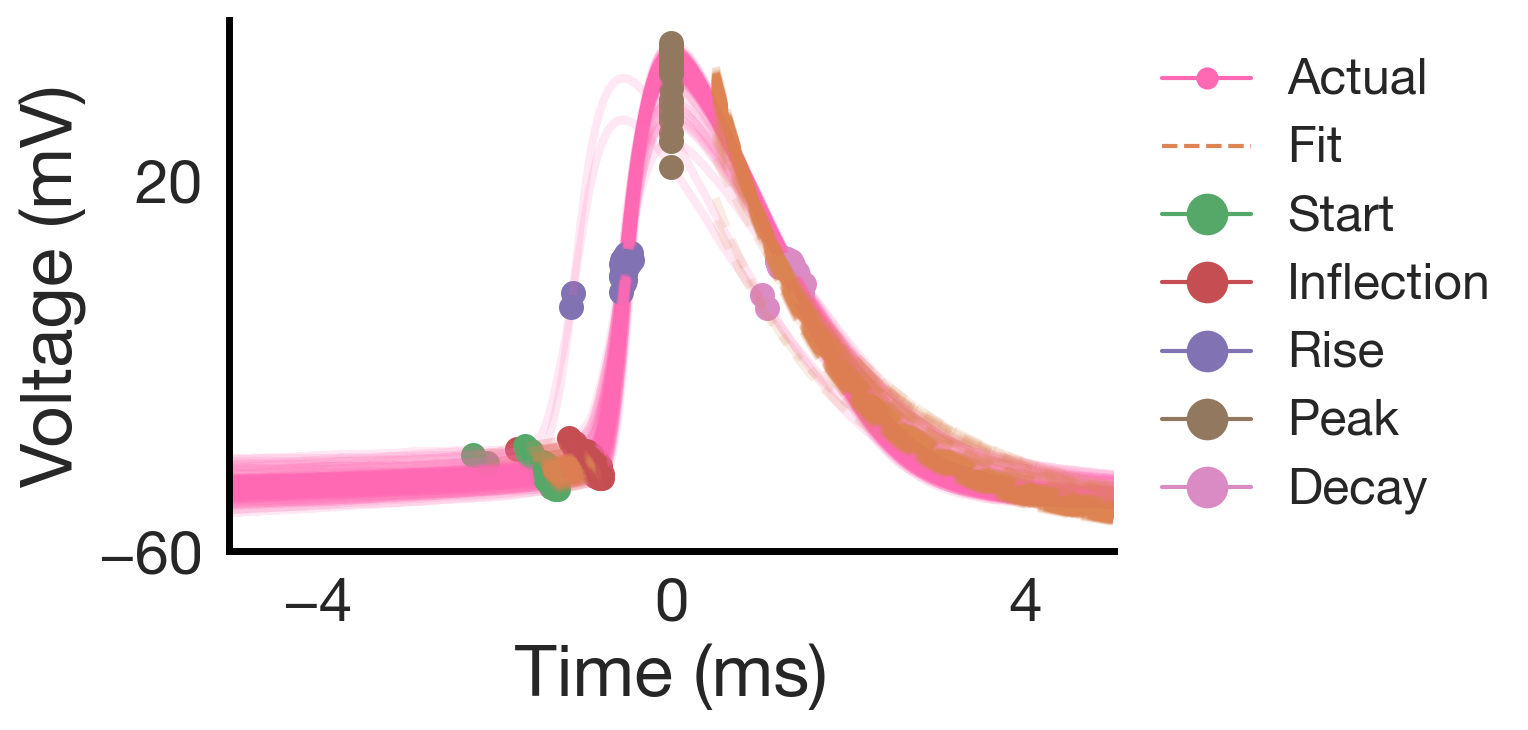

In [14]:
plot_pink_spikes(sp, indices_to_plot)

### 4a.2 Average Waveform by Stimulus Type

Mean ± SD spike waveform for each stimulus type (constant / ramp / pink noise).

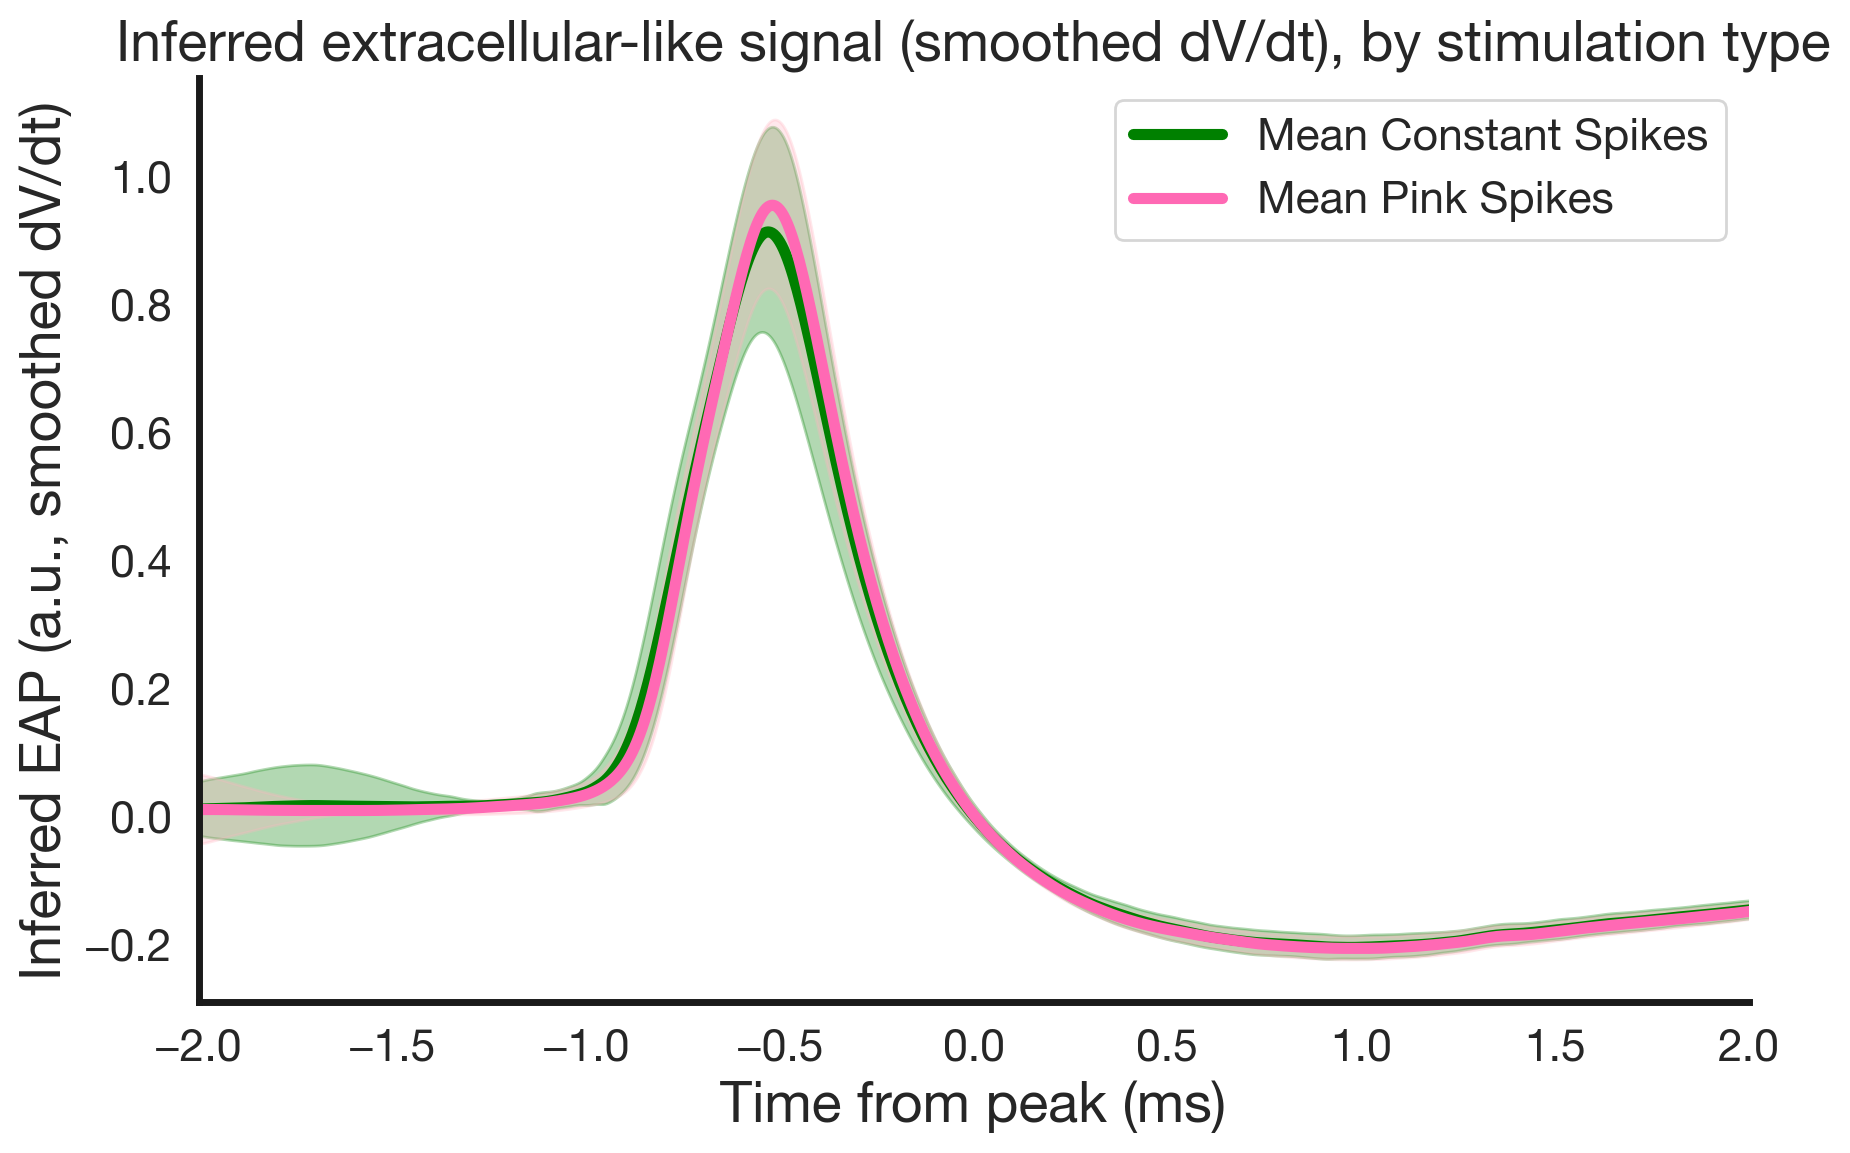

In [15]:
plot_avg_waveform_by_stim_type(all_contant_spks, None, all_pink_spks)

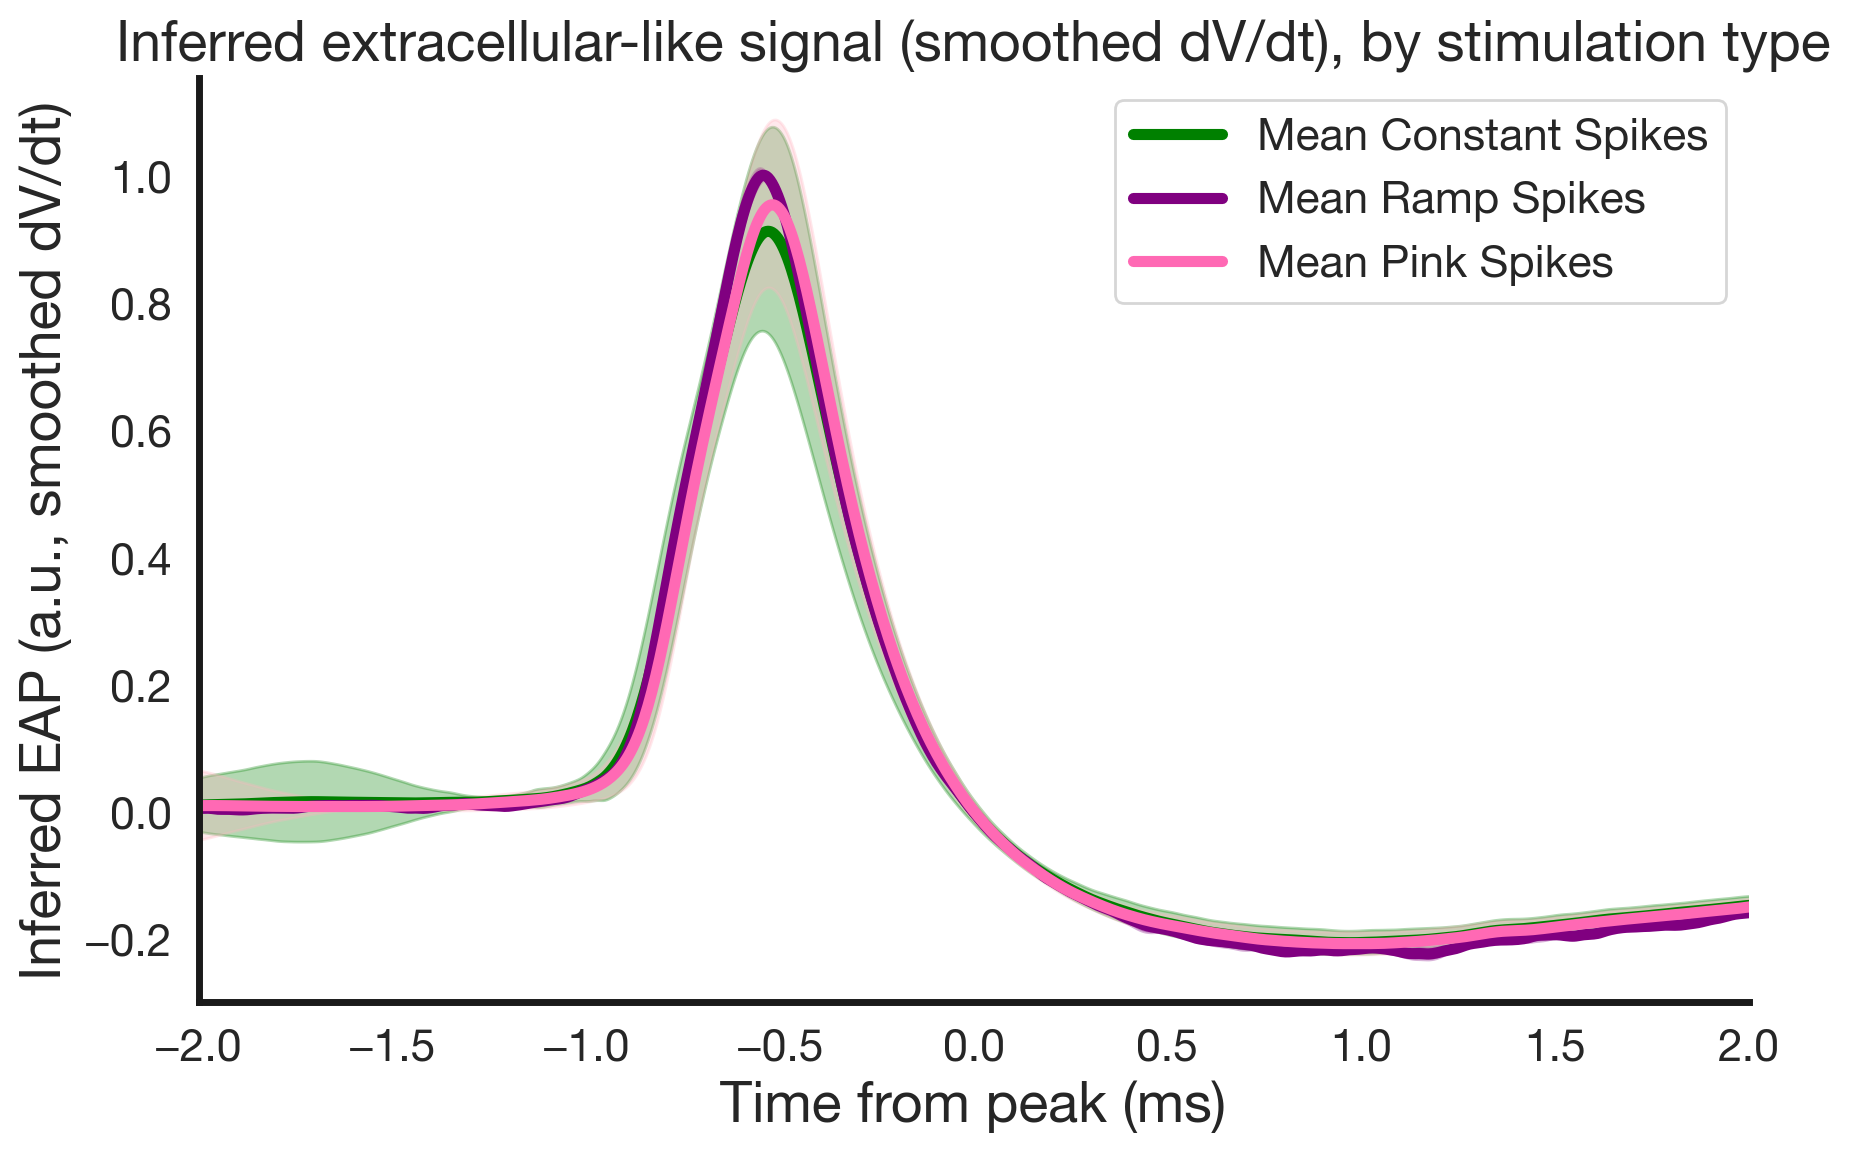

In [16]:
plot_avg_waveform_by_stim_type(all_contant_spks, all_ramp_spks, all_pink_spks)

### 4b. Last-Spike-of-Sweep Filtering

The last spike of each sweep is excluded — these spikes have inflated ISIs (no successor spike) that skew the log ISI distribution.

In [17]:
last_spikes_indices = df.groupby('sweep').tail(1).index
print("Indices of last spikes in each sweep:", last_spikes_indices)

Indices of last spikes in each sweep: Int64Index([  1,   2,   3,  13,  14,  17,  21,  24,  25,  37,  47,  58,  65,
             86, 104, 120, 137, 138, 139, 143, 147, 150, 151, 163, 173, 184,
            190, 211, 230, 247, 267, 268, 269, 275, 281, 286, 287, 301, 314,
            325, 337, 359, 379],
           dtype='int64')


### 4c. Correlation Scatter Plots — Pink Spikes

In [18]:
df_pink = df.loc[df['stim_type'] == 'pink']
# Find which indices are actually present in df_pink, remove last spike of sweeps
valid_indices = [idx for idx in last_spikes_indices if idx in df_pink.index]

# Drop the last spikes
df_pink_filtered = df_pink.drop(valid_indices)

df_pink_first = df_pink.loc[df_pink['spike_num'] == 0].copy()

In [19]:
_pkl_pink = os.path.join(PICKLE_DIR, 'df_pink_filtered_c2.pkl')
if FORCE_RERUN or not os.path.exists(_pkl_pink):
    with open(_pkl_pink, 'wb') as fh:
        pickle.dump(df_pink_filtered, fh)
    print('Saved df_pink_filtered_c2.pkl')

In [20]:
#get dfs for regression models 

df_pink_no_stim_filtered = df_pink_filtered.drop(['stim_exp', 'stim_mean', 'stim_std' ], axis=1)
df_pink_no_stim_first = df_pink_first.drop(['stim_exp', 'stim_mean', 'stim_std' ], axis=1)
df_pink_onlystim_filtered = df_pink_filtered.drop(['ramp_amp', 'inflection_time', 'inflection_amp', 'peak_amp', 'peak_width','peak_sharpness', 'exp_lambda', 'exp_const' ], axis=1)
df_pink_onlystim_first = df_pink_first.drop(['ramp_amp', 'inflection_time', 'inflection_amp', 'peak_amp', 'peak_width','peak_sharpness', 'exp_lambda', 'exp_const' ], axis=1)


Pairwise spike x stim correlations (5 ms window), BH-FDR across 24 tests:
stim_target   spike_feature   n         r            p        q_fdr  sig_fdr
   stim_exp      peak_width 270  0.122733 4.390789e-02 1.631378e-01    False
   stim_exp inflection_time 270  0.120684 4.758187e-02 1.631378e-01    False
   stim_exp  peak_sharpness 270 -0.089716 1.414773e-01 3.208404e-01    False
   stim_exp  inflection_amp 270  0.087900 1.497467e-01 3.208404e-01    False
   stim_exp        peak_amp 270 -0.081871 1.798280e-01 3.319901e-01    False
   stim_exp      exp_lambda 270 -0.076420 2.106724e-01 3.611527e-01    False
   stim_exp       exp_const 270  0.041124 5.010191e-01 5.961152e-01    False
   stim_exp        ramp_amp 270  0.010481 8.638868e-01 9.117212e-01    False
  stim_mean      peak_width 270  0.374400 2.068552e-10 4.964526e-09     True
  stim_mean      exp_lambda 270 -0.328890 3.132724e-08 3.759269e-07     True
  stim_mean        peak_amp 270 -0.248258 3.705161e-05 2.964129e-04     True
  



In [21]:
plot_top_correlations_by_window(df_pink_filtered, window_ms=5)


## 5. Classification: Decoding Stimulus Type

Same three-classifier comparison as cell 1 (logistic regression, SVM, random forest). A consistent above-chance accuracy across both cells would strongly support stimulus-driven waveform modulation as a robust phenomenon.

### 5a. Data Preparation

Drop NaNs, build feature matrix X (waveform features only) and target y (stimulus type), then split into 80/20 train/test.

In [22]:
df = df.dropna(subset=['stim_type'])

X = df.drop(columns=['stim_type', 'spike_num', 'sweep', 'stim_exp','stim_mean','stim_std', 'pink_type',
                      'log_isi', 'log_isi_prev', 'n_spikes_50ms', 'n_spikes_200ms'],
            inplace=False)  # waveform features only - same rationale as excluding log_isi
y = df['stim_type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5b. Logistic Regression

In [23]:
pickle_path_model = os.path.join(PICKLE_DIR, 'logr_model2.pkl')
pickle_path_accs  = os.path.join(PICKLE_DIR, 'logr_accs2.pkl')

if not FORCE_RERUN and os.path.exists(pickle_path_model):
    try:
        with open(pickle_path_model, 'rb') as file:
            logr_model = pickle.load(file)
        with open(pickle_path_accs, 'rb') as file:
            logr_accs = pickle.load(file)
        print('Loaded logr_model and logr_accs from pickle.')
    except Exception as e:
        print(f'Pickle load failed ({e}), retraining...')
        FORCE_RERUN = True

if FORCE_RERUN or not os.path.exists(pickle_path_model):
    logr_model, logr_accs = logistic_regression_stim(X, y, X_train, X_test, y_train, y_test)
    with open(pickle_path_model, 'wb') as file:
        pickle.dump(logr_model, file)
    with open(pickle_path_accs, 'wb') as file:
        pickle.dump(logr_accs, file)
    print('Trained and saved logr_model and logr_accs to pickle.')


Loaded logr_model and logr_accs from pickle.


In [24]:
logr_acc = logr_model.score(X_test, y_test)


### 5c. SVM

In [25]:
pickle_path_model = os.path.join(PICKLE_DIR, 'svm_model2.pkl')
pickle_path_accs  = os.path.join(PICKLE_DIR, 'svm_accs2.pkl')

if not FORCE_RERUN and os.path.exists(pickle_path_model):
    try:
        with open(pickle_path_model, 'rb') as file:
            svm_model = pickle.load(file)
        with open(pickle_path_accs, 'rb') as file:
            svm_accs = pickle.load(file)
        print('Loaded svm_model and svm_accs from pickle.')
    except Exception as e:
        print(f'Pickle load failed ({e}), retraining...')
        FORCE_RERUN = True

if FORCE_RERUN or not os.path.exists(pickle_path_model):
    svm_model, svm_accs = svm_stim(X, y, X_train, X_test, y_train, y_test)
    with open(pickle_path_model, 'wb') as file:
        pickle.dump(svm_model, file)
    with open(pickle_path_accs, 'wb') as file:
        pickle.dump(svm_accs, file)
    print('Trained and saved svm_model and svm_accs to pickle.')


Loaded svm_model and svm_accs from pickle.


In [26]:
svm_acc = svm_model.score(X_test, y_test)

### 5d. Random Forest

In [27]:
_mask = pd.notna(y_train) & pd.notna(y_test)
y_train_clean = y_train[pd.notna(y_train)]
X_train_clean = X_train.loc[y_train_clean.index]
y_test_clean  = y_test[pd.notna(y_test)]
X_test_clean  = X_test.loc[y_test_clean.index]

pickle_path_model = os.path.join(PICKLE_DIR, 'rf_model2.pkl')
pickle_path_accs  = os.path.join(PICKLE_DIR, 'rf_accs2.pkl')
pickle_path_imps  = os.path.join(PICKLE_DIR, 'rf_importances2.pkl')

if not FORCE_RERUN and os.path.exists(pickle_path_model) and os.path.exists(pickle_path_imps):
    try:
        with open(pickle_path_model, 'rb') as file:
            rf_model = pickle.load(file)
        with open(pickle_path_accs, 'rb') as file:
            rf_accs = pickle.load(file)
        with open(pickle_path_imps, 'rb') as file:
            rf_importances = pickle.load(file)
        print('Loaded rf_model, rf_accs, rf_importances from pickle.')
    except Exception as e:
        print(f'Pickle load failed ({e}), retraining...')
        FORCE_RERUN = True

if FORCE_RERUN or not os.path.exists(pickle_path_model) or not os.path.exists(pickle_path_imps):
    rf_model, rf_accs, rf_importances = random_forest_stim(
        X_train_clean, y_train_clean, X_train_clean, X_test_clean, y_train_clean, y_test_clean)
    with open(pickle_path_model, 'wb') as file:
        pickle.dump(rf_model, file)
    with open(pickle_path_accs, 'wb') as file:
        pickle.dump(rf_accs, file)
    with open(pickle_path_imps, 'wb') as file:
        pickle.dump(rf_importances, file)
    print('Trained and saved rf_model, rf_accs, rf_importances to pickle.')

Loaded rf_model, rf_accs, rf_importances from pickle.


In [28]:
# Calculate average accuracy
rf_avg_accs = np.mean(rf_accs)

rf_stdev_accs = np.std(rf_accs)

### 5e. Model Comparison

In [29]:
print(f"Accuracy Logistic Regression: {logr_acc: .3f}")
print(f"Accuracy SVM: {svm_acc: .3f}")
print(f"Mean Accuracy Random Forest: {rf_avg_accs: .3f}")
print(f"Stdev Accuracy Random Forest: {rf_stdev_accs: .3f}")

Accuracy Logistic Regression:  0.829
Accuracy SVM:  0.829
Mean Accuracy Random Forest:  0.861
Stdev Accuracy Random Forest:  0.036


#### Stimulus classification — cell 2 note

Cell 2 has pronounced class imbalance (majority pink, few constant, only one ramp sweep). This imbalance inflates bootstrap accuracy variance and limits interpretability of the three-class classifier results. The ridge regression for continuous stimulus statistics (stim_mean, stim_std, stim_exp) and log ISI prediction remain valid and are the primary results for this cell.

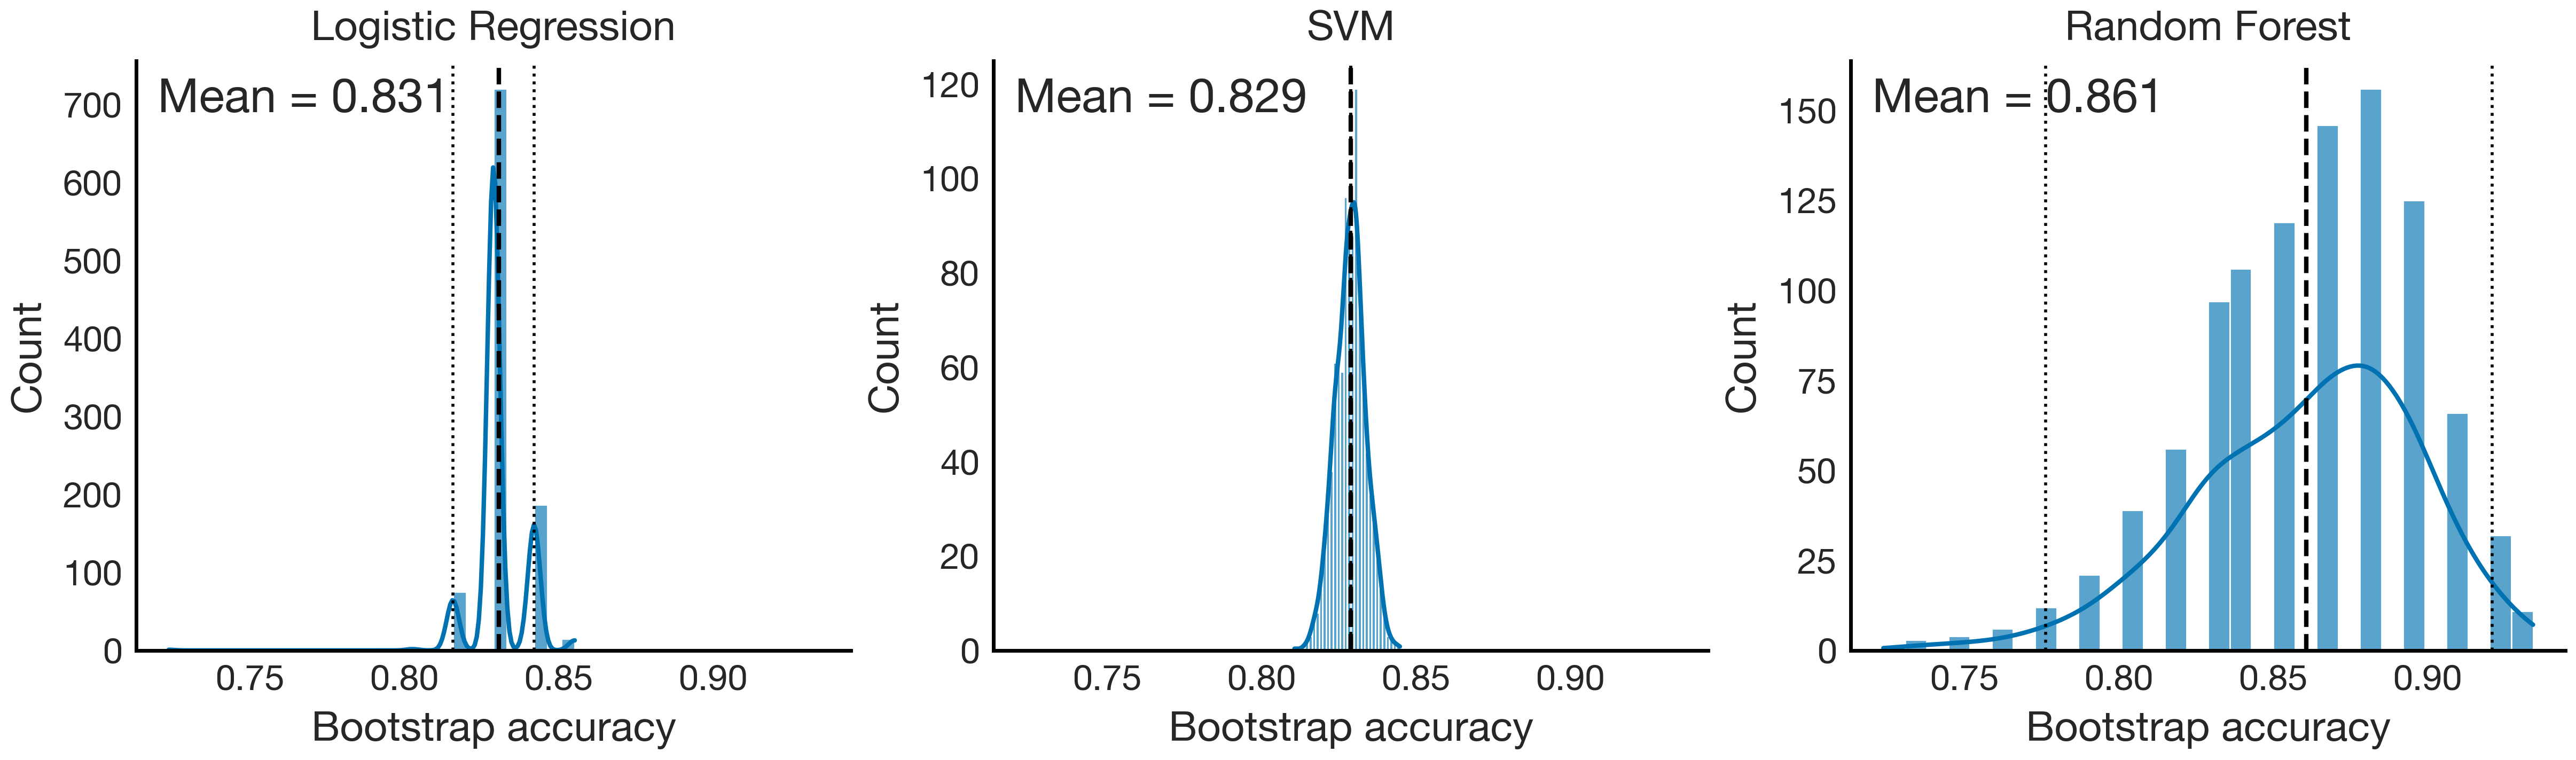

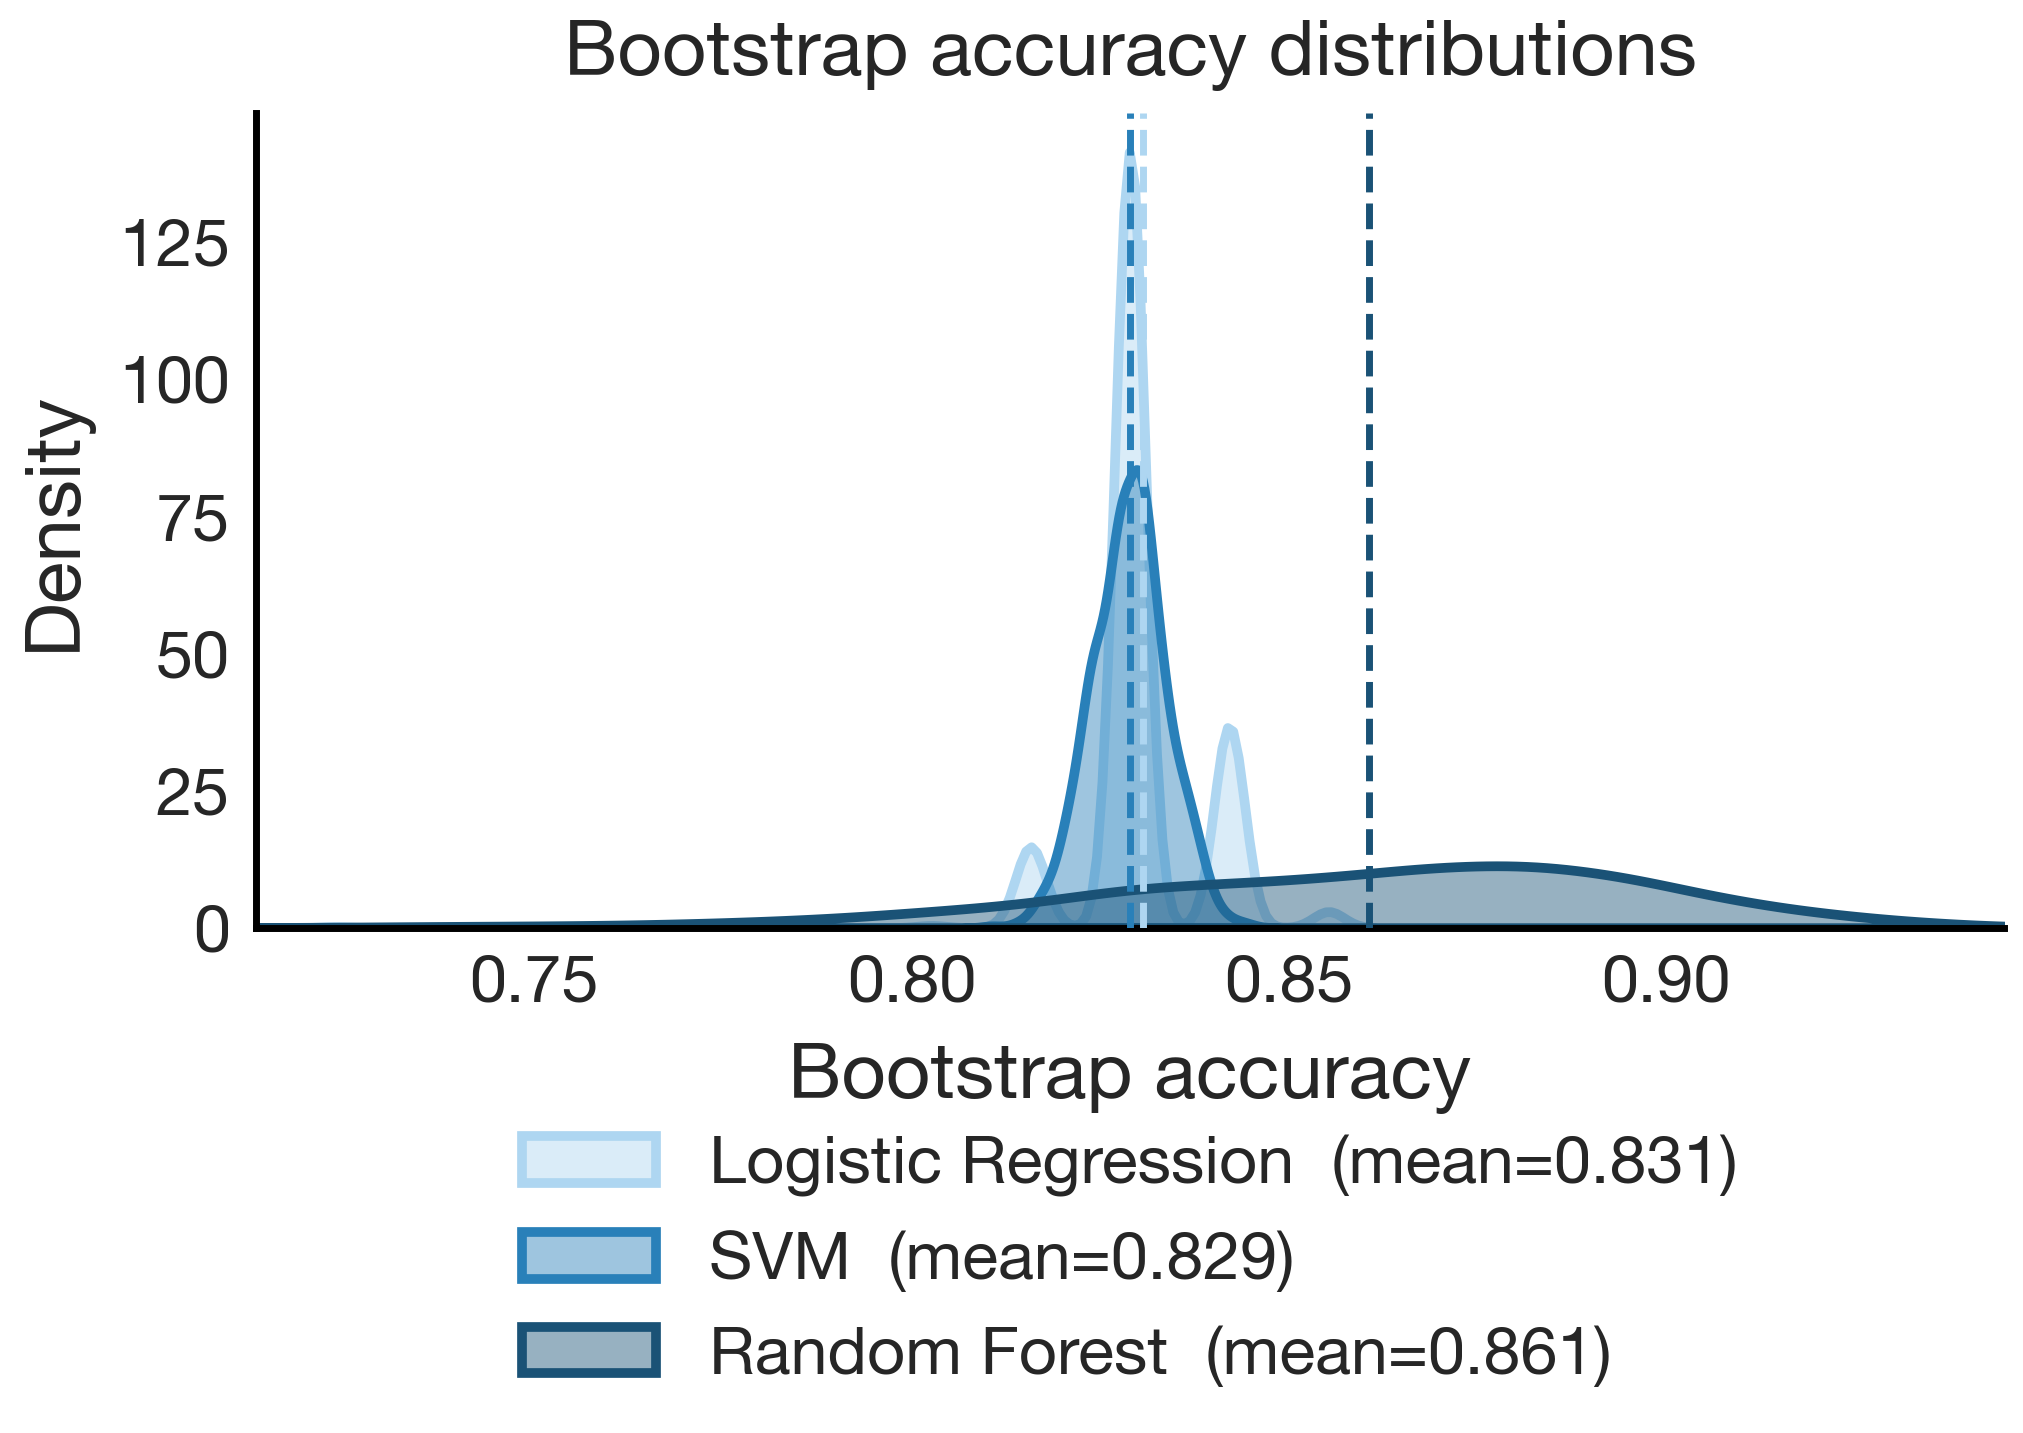

In [30]:
plot_bootstrap_histograms([logr_accs, svm_accs, rf_accs], ["Logistic Regression", "SVM", "Random Forest"])
plot_bootstrap_histograms([logr_accs, svm_accs, rf_accs], ["Logistic Regression", "SVM", "Random Forest"], overlay=True)

Best 3-class model: Random Forest  (mean acc = 0.861)


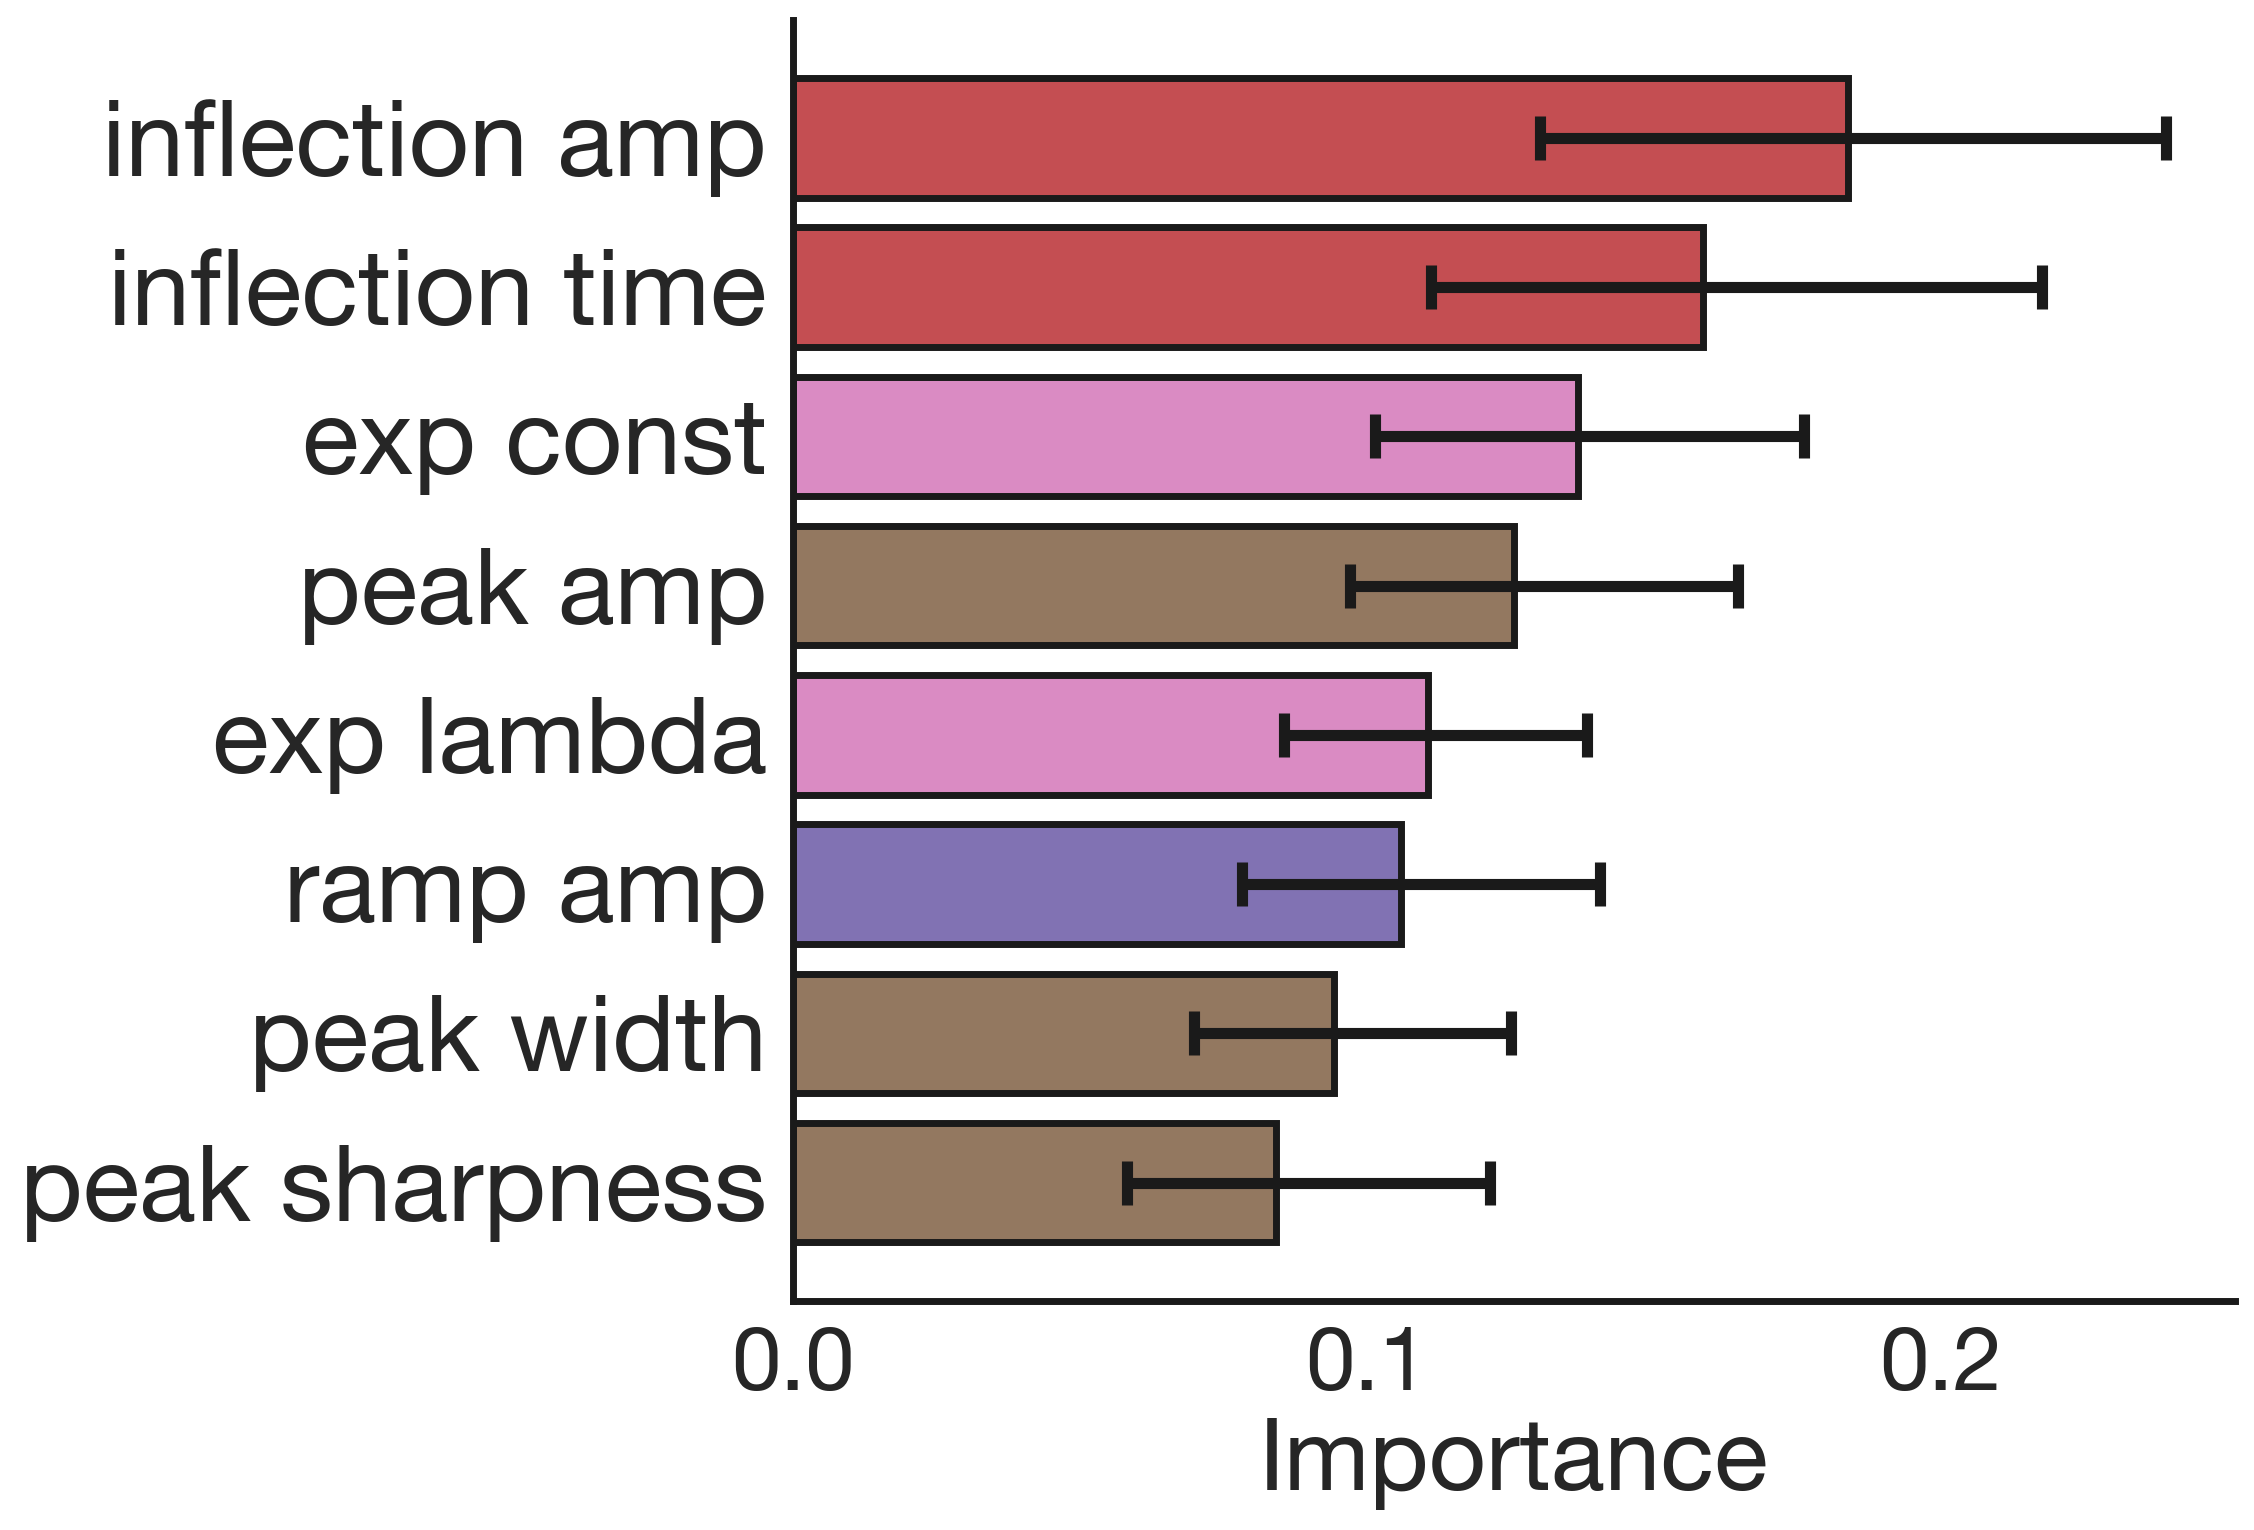

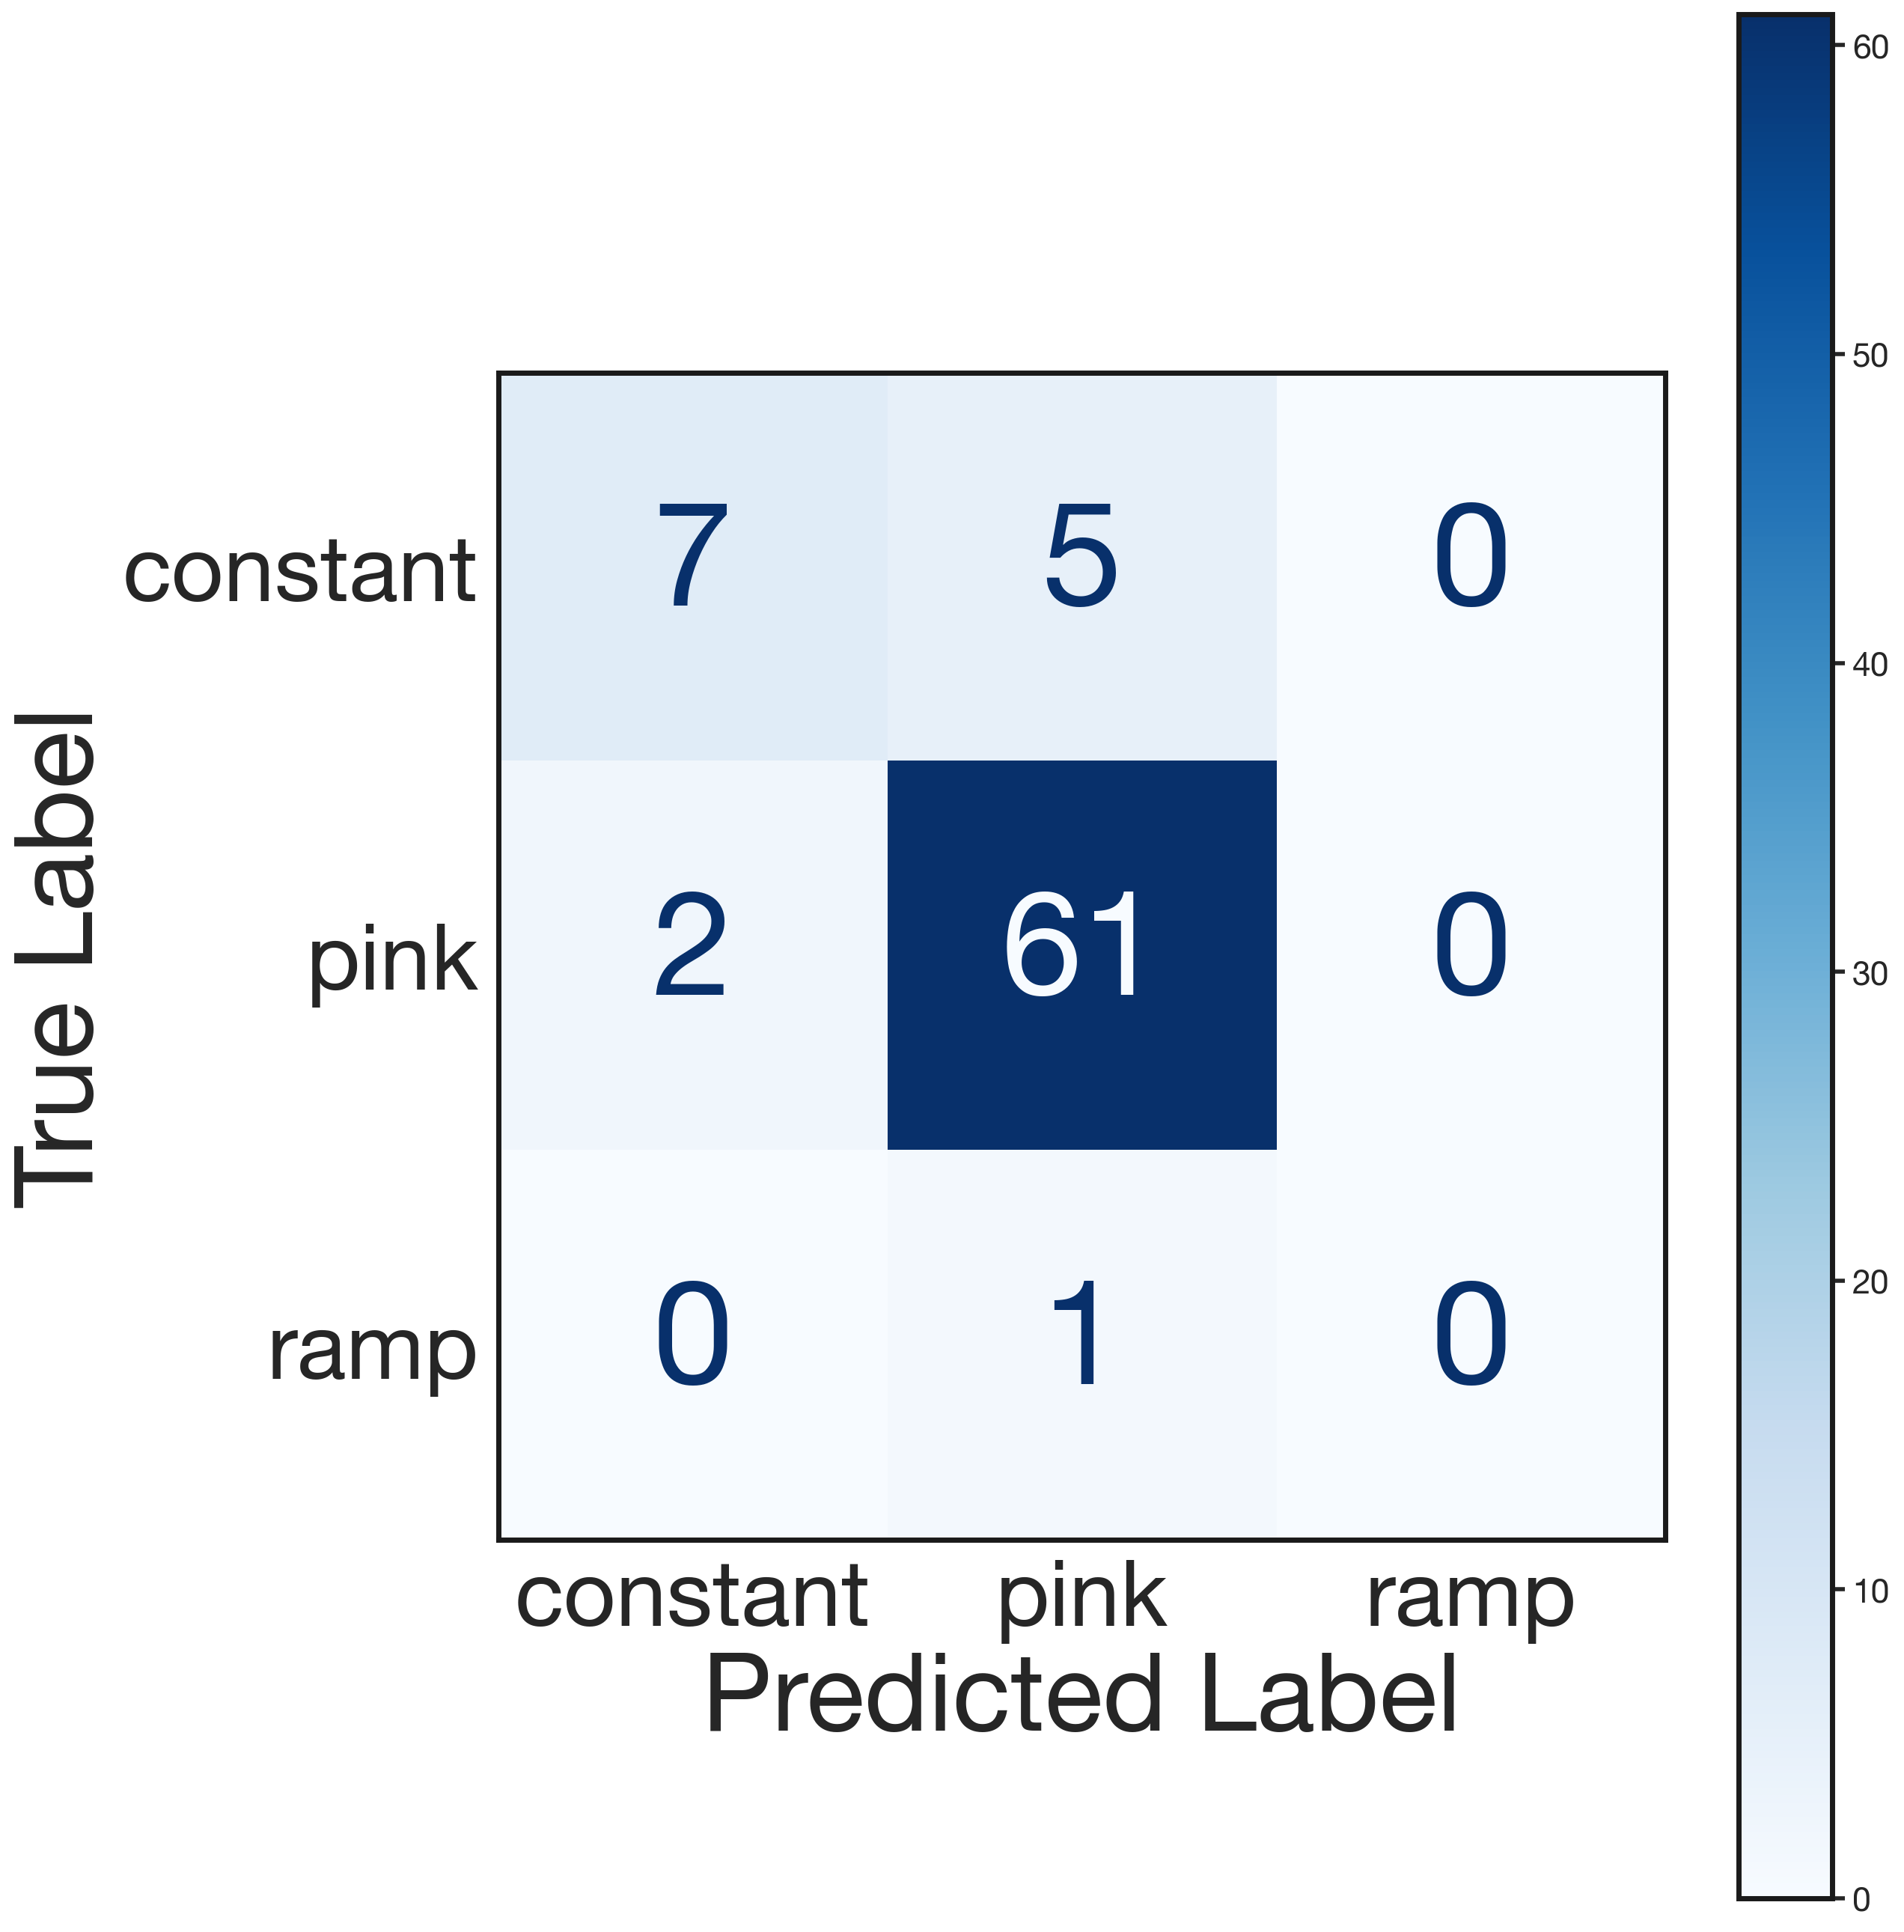

In [31]:
# ── Best 3-class model by mean bootstrap accuracy ────────────────────────────
_reg3 = {
    'Random Forest':       (rf_model,   rf_accs,   rf_importances, X_test, y_test),
    'Logistic Regression': (logr_model, logr_accs, None,           X_test, y_test),
    'SVM':                 (svm_model,  svm_accs,  None,           X_test, y_test),
}
_best3_name = max(_reg3, key=lambda k: np.mean(_reg3[k][1]))
_best3_model, _best3_accs, _best3_imps, _best3_X_te, _best3_y_te = _reg3[_best3_name]
print(f'Best 3-class model: {_best3_name}  (mean acc = {np.mean(_best3_accs):.3f})')

if _best3_imps is not None:
    plot_feature_importance_categorical(_best3_model, X, _best3_imps)
else:
    print(f'Feature importances not available for {_best3_name}.')

plot_confusion_matrix(_best3_model, _best3_X_te, _best3_y_te)

### 5f. Binary Classification: Constant vs. Pink

Cell 2 has pronounced class imbalance (few constant/ramp sweeps, majority pink). Ramp is excluded; we run a binary constant vs. pink classifier to make results interpretable.

Loaded logr binary from pickle.
Loaded svm binary from pickle.
Loaded rf binary from pickle.


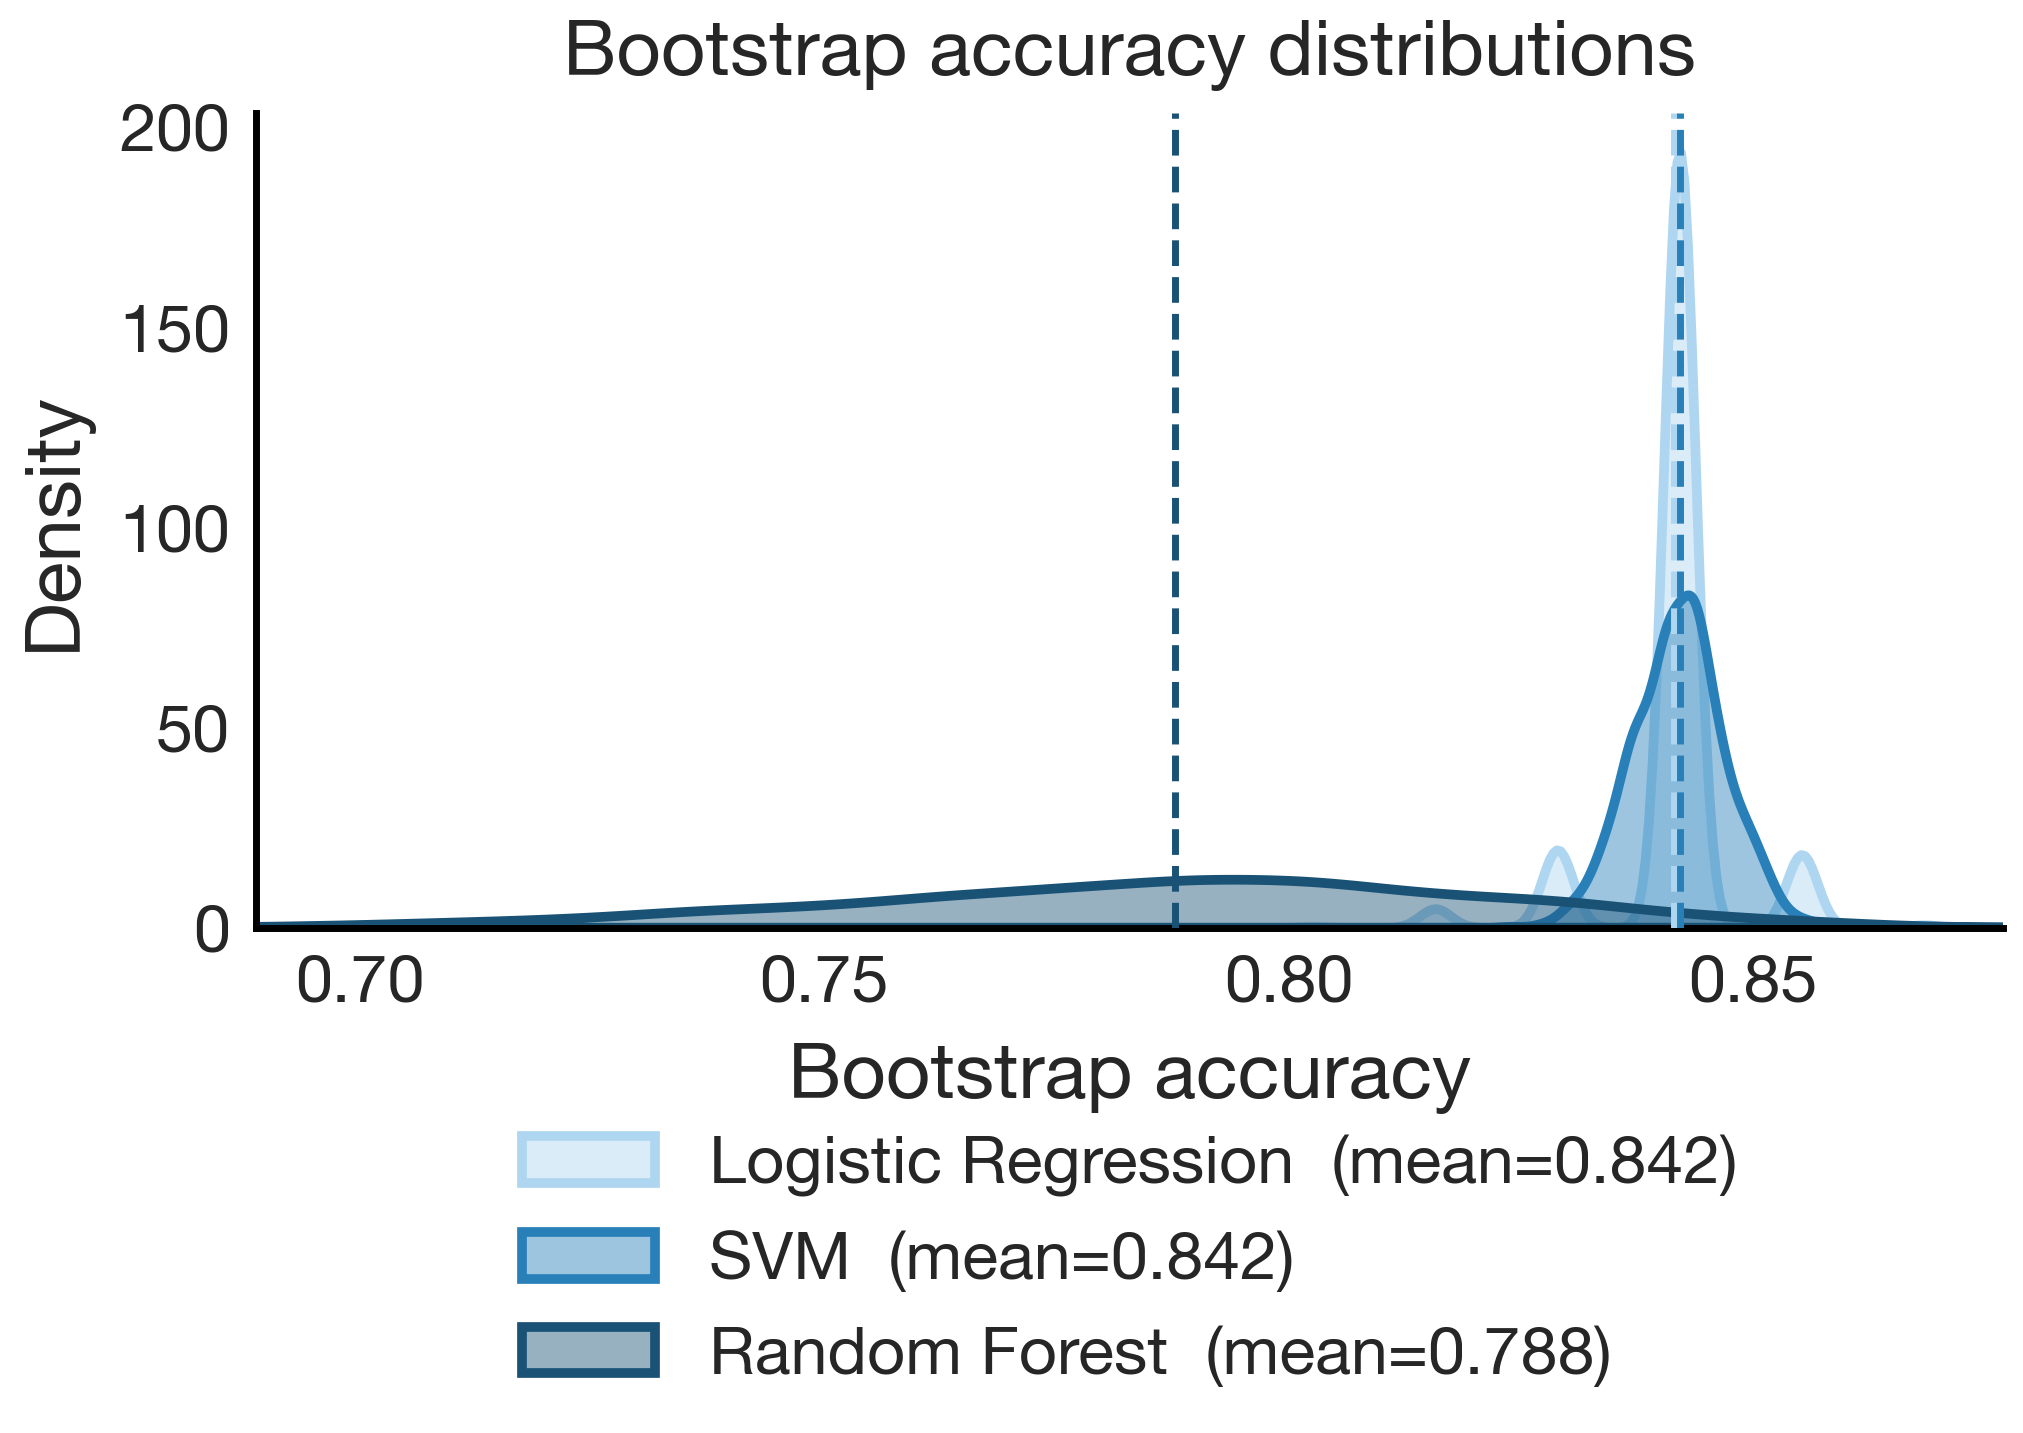

In [32]:
# Binary: constant vs. pink only (drop ramp)
df_binary = df[df['stim_type'].isin(['constant', 'pink'])].copy()
X_bin = df_binary.drop(columns=['stim_type', 'spike_num', 'sweep',
                                  'stim_exp', 'stim_mean', 'stim_std', 'pink_type', 'log_isi',
                                  'log_isi_prev', 'n_spikes_50ms', 'n_spikes_200ms'],
                         errors='ignore')
y_bin = df_binary['stim_type']
X_bin_tr, X_bin_te, y_bin_tr, y_bin_te = train_test_split(X_bin, y_bin, test_size=0.2, random_state=42)

_pdir = PICKLE_DIR
for _name, _pkl_m, _pkl_a, _fn in [
    ('logr', 'logr_model2_binary.pkl', 'logr_accs2_binary.pkl',
     lambda: logistic_regression_stim(X_bin, y_bin, X_bin_tr, X_bin_te, y_bin_tr, y_bin_te)),
    ('svm',  'svm_model2_binary.pkl',  'svm_accs2_binary.pkl',
     lambda: svm_stim(X_bin, y_bin, X_bin_tr, X_bin_te, y_bin_tr, y_bin_te)),
]:
    _pm = os.path.join(_pdir, _pkl_m)
    _pa = os.path.join(_pdir, _pkl_a)
    if not FORCE_RERUN and os.path.exists(_pm):
        with open(_pm, 'rb') as fh: locals()[f'{_name}_model_bin'] = pickle.load(fh)
        with open(_pa, 'rb') as fh: locals()[f'{_name}_accs_bin']  = pickle.load(fh)
        print(f'Loaded {_name} binary from pickle.')
    else:
        _model, _accs = _fn()
        locals()[f'{_name}_model_bin'] = _model
        locals()[f'{_name}_accs_bin']  = _accs
        with open(_pm, 'wb') as fh: pickle.dump(_model, fh)
        with open(_pa, 'wb') as fh: pickle.dump(_accs, fh)
        print(f'Trained and saved {_name} binary.')

# RF binary
_pm = os.path.join(_pdir, 'rf_model2_binary.pkl')
_pa = os.path.join(_pdir, 'rf_accs2_binary.pkl')
_pi = os.path.join(_pdir, 'rf_importances2_binary.pkl')
y_bin_tr_c = y_bin_tr[pd.notna(y_bin_tr)]; X_bin_tr_c = X_bin_tr.loc[y_bin_tr_c.index]
y_bin_te_c = y_bin_te[pd.notna(y_bin_te)]; X_bin_te_c = X_bin_te.loc[y_bin_te_c.index]
if not FORCE_RERUN and os.path.exists(_pm):
    with open(_pm, 'rb') as fh: rf_model_bin = pickle.load(fh)
    with open(_pa, 'rb') as fh: rf_accs_bin  = pickle.load(fh)
    with open(_pi, 'rb') as fh: rf_imps_bin  = pickle.load(fh)
    print('Loaded rf binary from pickle.')
else:
    rf_model_bin, rf_accs_bin, rf_imps_bin = random_forest_stim(
        X_bin_tr_c, y_bin_tr_c, X_bin_tr_c, X_bin_te_c, y_bin_tr_c, y_bin_te_c)
    with open(_pm, 'wb') as fh: pickle.dump(rf_model_bin, fh)
    with open(_pa, 'wb') as fh: pickle.dump(rf_accs_bin,  fh)
    with open(_pi, 'wb') as fh: pickle.dump(rf_imps_bin,  fh)
    print('Trained and saved rf binary.')

plot_bootstrap_histograms(
    [logr_accs_bin, svm_accs_bin, rf_accs_bin],
    ['Logistic Regression', 'SVM', 'Random Forest'],
    overlay=True,
)

In [33]:
# ── Best binary model by mean bootstrap accuracy ──────────────────────────────
_reg_bin = {
    'Random Forest':       (rf_model_bin,   rf_accs_bin,   rf_imps_bin,  X_bin_te, y_bin_te),
    'Logistic Regression': (logr_model_bin, logr_accs_bin, None,         X_bin_te, y_bin_te),
    'SVM':                 (svm_model_bin,  svm_accs_bin,  None,         X_bin_te, y_bin_te),
}
_best_bin_name = max(_reg_bin, key=lambda k: np.mean(_reg_bin[k][1]))
_best_bin_model, _best_bin_accs, _best_bin_imps, _best_bin_X_te, _best_bin_y_te = _reg_bin[_best_bin_name]
print(f'Best binary model: {_best_bin_name}  (mean acc = {np.mean(_best_bin_accs):.3f})')

if _best_bin_imps is not None:
    plot_feature_importance_categorical(_best_bin_model, X_bin, _best_bin_imps)
else:
    print(f'Feature importances not available for {_best_bin_name}.')

Best binary model: SVM  (mean acc = 0.842)
Feature importances not available for SVM.


## 6. Regression: Predicting Stimulus Statistics

### 6a. Ridge Regression

Using ridge regression (k-fold CV), we predict instantaneous pink noise stimulus properties (exponent, mean, std) from spike waveform features. R² tells us how much variance in the stimulus is captured by waveform shape alone.

In [ ]:
pickle_path = os.path.join(PICKLE_DIR, 'ridge_results_stim_stats2.pkl')

if not FORCE_RERUN and os.path.exists(pickle_path):
    with open(pickle_path, 'rb') as file:
        ridge_results_dict = pickle.load(file)
    print('Loaded ridge_results_dict from pickle.')
else:
    ridge_results_dict = {}
    for stim_feature in ['stim_exp', 'stim_mean', 'stim_std']:
        print(f'\n--- Processing {stim_feature} ---\n')
        data = df_pink_filtered.dropna(subset=[stim_feature])
        X = data.drop(columns=['stim_exp', 'stim_mean', 'stim_std', 'log_isi'])
        y = data[stim_feature]
        ridge_results_dict[stim_feature] = run_ridge_regression_kfold(X, y)
    with open(pickle_path, 'wb') as file:
        pickle.dump(ridge_results_dict, file)
    print('Saved ridge_results_dict to pickle.')


### 6b. Results

In [ ]:
_targets = ['stim_exp', 'stim_mean', 'stim_std']
plot_ridge_results_grid(
    ridge_results_dict, keys=_targets,
    labels=['stim exp', 'stim mean', 'stim std'],
)
apply_fdr_pvc6(ridge_results_dict)

## 7. Pre-Spike Stimulus Window Analysis

### 7a. Window Expansion

We re-extract `stim_mean`, `stim_std`, and `stim_exp` using wider pre-inflection windows (5 → 500 ms) and re-run the spike waveform ridge regression to test whether the expanded window improves R².

Window choice mirrors the spe-1 pre-spike window (PRE\_WIN = −55 → −5 ms, i.e. 50 ms).

In [ ]:
if 'df_pink_raw_filtered' not in vars():
    df_pink_raw = df.loc[df['stim_type'] == 'pink']
    valid_idx_raw = [i for i in last_spikes_indices if i in df_pink_raw.index]
    df_pink_raw_filtered = df_pink_raw.drop(valid_idx_raw)

WINDOWS_MS  = [5, 25, 50, 100, 200, 300, 400, 500]
pickle_path = os.path.join(PICKLE_DIR, 'results_window2.pkl')

_required = (
    {f'{w}ms_{t}'      for w in WINDOWS_MS for t in ['stim_mean', 'stim_std', 'stim_exp']}
  | {f'shuf_{w}ms_{t}' for w in WINDOWS_MS for t in ['stim_mean', 'stim_std', 'stim_exp']}
)

if not FORCE_RERUN and os.path.exists(pickle_path):
    try:
        with open(pickle_path, 'rb') as file:
            results_window2 = pickle.load(file)
        print(f'Loaded results_window2 ({len(results_window2)} entries).')
    except Exception as _e:
        print(f'Pickle load failed ({_e}); recomputing.')
        results_window2 = {}
else:
    results_window2 = {}

_missing_windows = [w for w in WINDOWS_MS
                    if any(f'{w}ms_{t}' not in results_window2
                           for t in ['stim_mean', 'stim_std', 'stim_exp'])]
_missing_shuffle = [w for w in WINDOWS_MS
                    if any(f'shuf_{w}ms_{t}' not in results_window2
                           for t in ['stim_mean', 'stim_std', 'stim_exp'])]

if _missing_windows or _missing_shuffle:
    _rng = np.random.default_rng(42)

    if _missing_windows:
        print(f'Computing missing windows: {_missing_windows}')
        for wms in _missing_windows:
            if wms == 5:
                df_w = df_pink_filtered.copy()
            else:
                stim_extra = recompute_stim_features(f, fs, df_pink_raw_filtered, one_ms, window_ms=wms)
                df_w = df_pink_filtered.copy()
                df_w['stim_mean'] = stim_extra[f'stim_mean_{wms}ms']
                df_w['stim_std']  = stim_extra[f'stim_std_{wms}ms']
                df_w['stim_exp']  = stim_extra[f'stim_exp_{wms}ms']
                df_w = df_w.dropna(subset=['stim_mean'])
            for target in ['stim_mean', 'stim_std', 'stim_exp']:
                data_t = df_w.dropna(subset=[target])
                X_t = data_t.drop(columns=['stim_exp', 'stim_mean', 'stim_std', 'log_isi'])
                y_t = data_t[target]
                print(f'\n--- {wms} ms | {target} ---')
                results_window2[f'{wms}ms_{target}'] = run_ridge_regression_kfold(X_t, y_t)

    if _missing_shuffle:
        print(f'\nComputing shuffle controls for windows: {_missing_shuffle}')
        for wms in _missing_shuffle:
            if wms == 5:
                df_w = df_pink_filtered.copy()
            else:
                stim_extra = recompute_stim_features(f, fs, df_pink_raw_filtered, one_ms, window_ms=wms)
                df_w = df_pink_filtered.copy()
                df_w['stim_mean'] = stim_extra[f'stim_mean_{wms}ms']
                df_w['stim_std']  = stim_extra[f'stim_std_{wms}ms']
                df_w['stim_exp']  = stim_extra[f'stim_exp_{wms}ms']
                df_w = df_w.dropna(subset=['stim_mean'])
            for target in ['stim_mean', 'stim_std', 'stim_exp']:
                data_t = df_w.dropna(subset=[target])
                X_t    = data_t.drop(columns=['stim_exp', 'stim_mean', 'stim_std', 'log_isi'])
                y_shuf = pd.Series(_rng.permutation(data_t[target].values), index=data_t.index)
                print(f'\n--- shuf {wms} ms | {target} ---')
                results_window2[f'shuf_{wms}ms_{target}'] = run_ridge_regression_kfold(X_t, y_shuf)

    with open(pickle_path, 'wb') as file:
        pickle.dump(results_window2, file)
    print('\nSaved updated results_window2 to pickle.')
else:
    print('All windows (including shuffle controls) already computed.')

_shuf_results2 = {f'{w}ms_{t}': results_window2[f'shuf_{w}ms_{t}']
         for w in WINDOWS_MS for t in ['stim_mean', 'stim_std', 'stim_exp']
         if f'shuf_{w}ms_{t}' in results_window2} or None

plot_window_expansion(
    results_window2, WINDOWS_MS,
    targets=('stim_mean', 'stim_std', 'stim_exp'),
    target_labels=('stim mean', 'stim std', 'stim exp'),
    shuffle_results=_shuf_results2,
)


In [ ]:
# Cache stim_extra for each window (Cell 2) so the dataset summary notebook can load them
for wms in WINDOWS_MS:
    _cache_path = os.path.join(PICKLE_DIR, f'_stim_extra_{wms}ms_c2.pkl')
    if not FORCE_RERUN and os.path.exists(_cache_path):
        continue
    if wms == 5:
        _se = df_pink_raw_filtered[['stim_mean', 'stim_std', 'stim_exp']].copy()
        _se.columns = [f'stim_mean_5ms', f'stim_std_5ms', f'stim_exp_5ms']
    else:
        _se = recompute_stim_features(f, fs, df_pink_raw_filtered, one_ms, window_ms=wms)
    with open(_cache_path, 'wb') as _fh:
        pickle.dump(_se, _fh)
    print(f'Saved _stim_extra_{wms}ms_c2.pkl')
print('Done caching Cell 2 stim_extra.')

### 7b. Ridge Regression Results — Best Window

In [ ]:
_targets = ['stim_mean', 'stim_std', 'stim_exp']

# Per-feature best window: each stim target gets its own best window independently
_best_wms = {
    t: max(WINDOWS_MS, key=lambda w: results_window2[f'{w}ms_{t}']['r2_mean'])
    for t in _targets
}
for t, w in _best_wms.items():
    print(f'Best window for {t}: {w} ms  (R² = {results_window2[f"{w}ms_{t}"]["r2_mean"]:.3f})')

_keys   = [f'{_best_wms[t]}ms_{t}' for t in _targets]
_labels = [f'stim {t.split("_")[1]} ({_best_wms[t]} ms)' for t in _targets]
plot_ridge_results_grid(
    results_window2, keys=_keys,
    labels=_labels,
)
apply_fdr_pvc6({t: results_window2[f'{_best_wms[t]}ms_{t}'] for t in _targets})

### 7c. Top Spike–Stim Correlations by Window

In [ ]:
for wms in WINDOWS_MS:
    df_w = prepare_window_df(df_pink_filtered, df_pink_raw_filtered, f, fs, one_ms, wms)
    plot_top_correlations_by_window(df_w, window_ms=wms, top=True)

### 7d. Top Correlations — Best Window (all 3 stim features)

In [ ]:
# Per-feature best window correlations: each stim row uses its own best-window df_w
_df_w_per_feat = {
    t: prepare_window_df(df_pink_filtered, df_pink_raw_filtered, f, fs, one_ms, _best_wms[t])
    for t in ['stim_mean', 'stim_std', 'stim_exp']
}
plot_top_correlations_by_window(
    None, window_ms=_best_wms, top=True, df_w_dict=_df_w_per_feat
)

## 8. Beta Weights & R² Summary

Lollipop forest plot of significant bootstrapped beta weights and bootstrapped R² using per-feature best windows (stim_mean, stim_std, stim_exp each use the window that maximizes their individual R²).

In [ ]:
plot_beta_weights_combined(results_window2, window_ms=_best_wms)

---
## Repeated out-of-fold CV (same fix as cell 1)

The binary constant-vs-pink confusion matrix above (`plot_confusion_matrix(_best_bin_model, X_bin_te, y_bin_te)`) has the same issue as cell 1's original: it's graded against a single fixed 20% test split, and the reported bootstrap accuracy resamples the training data but always evaluates against that same fixed split. Replacing with repeated 5-fold CV: every spike gets an out-of-fold prediction each repeat, and repeating with fresh random folds gives a proper accuracy distribution instead of one bootstrapped-training/fixed-test number. Using the RF classifier specifically (matching the cell 1 analysis and typically the strongest of the three model types).

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

print(f'Binary (constant vs pink) spikes: {len(X_bin)}  counts: {y_bin.value_counts().to_dict()}')

best_params_bin = {k: v for k, v in rf_model_bin.get_params().items() if k not in ('class_weight',)}
labels_bin = rf_model_bin.classes_

N_REPEATS = 1000
rep_acc_bin = np.zeros(N_REPEATS)
rep_cm_bin = np.zeros((N_REPEATS, len(labels_bin), len(labels_bin)))

for rep in range(N_REPEATS):
    cv_rep = StratifiedKFold(n_splits=5, shuffle=True, random_state=rep)
    y_pred_rep = cross_val_predict(
        RandomForestClassifier(**best_params_bin, class_weight=None), X_bin, y_bin, cv=cv_rep)
    rep_acc_bin[rep] = accuracy_score(y_bin, y_pred_rep)
    rep_cm_bin[rep] = confusion_matrix(y_bin, y_pred_rep, labels=labels_bin)

print(f'Out-of-fold accuracy across {N_REPEATS} repeated 5-fold splits: '
      f'{rep_acc_bin.mean():.3f} +/- {rep_acc_bin.std():.3f} '
      f'(min={rep_acc_bin.min():.3f}, max={rep_acc_bin.max():.3f})')
print(f'Original single-split bootstrap accuracy (for comparison): {np.mean(rf_accs_bin):.3f}')

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].hist(rep_acc_bin, bins=30, color='#00838F', edgecolor='white')
axes[0].axvline(rep_acc_bin.mean(), color='black', lw=2, ls='--',
                 label=f'mean = {rep_acc_bin.mean():.3f}')
axes[0].axvline(np.mean(rf_accs_bin), color='#d62728', lw=2, ls=':',
                 label=f'original bootstrap ({np.mean(rf_accs_bin):.3f})')
axes[0].set_xlabel('Out-of-fold accuracy', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Repeats', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11, frameon=False)
axes[0].set_title(f'{N_REPEATS} repeated 5-fold splits (binary)', fontsize=13, fontweight='bold')

mean_cm_bin = rep_cm_bin.mean(axis=0)
ConfusionMatrixDisplay(confusion_matrix=np.round(mean_cm_bin).astype(int),
                       display_labels=labels_bin).plot(cmap='Blues', ax=axes[1],
                                                        xticks_rotation=0, values_format='d')
for text in axes[1].texts:
    text.set_fontsize(16); text.set_fontweight('bold')
axes[1].set_title('Mean confusion matrix\n(averaged across repeats)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** the main figure above now uses out-of-fold predictions for all constant/pink spikes rather than only the held-out test split. The most robust accuracy estimate, from repeating the full out-of-fold procedure 1000x, is reported in the printed output above (mean +/- std across repeats) - that's the number to cite alongside cell 1's 78.4% +/- 0.7%. The averaged confusion matrix (right panel above) is the most stable version of this result available.